# 🖨️ Printing Defect Detection — YOLO26n Baseline (Phase 3, final baseline)

This notebook trains and evaluates a **YOLO26n** baseline on the same printing-defect
dataset (2435 images, 15 defect classes, 70:20:10 train/valid/test split, no
augmentation applied yet — only 512×512 resizing) using the same pipeline structure as
your YOLOv5s and YOLOv8s baselines, so all three are directly comparable.

**What this notebook does, step by step:**
1. Set up the local Jupyter environment and install the `ultralytics` package (YOLO26)
2. Load and fix `data.yaml`, upload/extract your dataset
3. Inspect the dataset (class balance, sample images) — with a special note on
   `ink_spots_on_paper`, which has far more annotations than the other 14 classes
4. Train YOLO26n from pretrained (COCO) weights, **with augmentation turned off**,
   matching your YOLOv5s and YOLOv8s baseline settings
5. Evaluate on the held-out **test** set: Precision, Recall, mAP@0.5, mAP@0.5:0.95, F1
6. Build a **class-wise performance table** for all 15 classes
7. Show the confusion matrix and training/evaluation plots
8. Run predictions on test images and save annotated example images
9. Summarize which defect classes are detected well vs. poorly
10. Save everything (weights + results) so you can compare against YOLOv5s and YOLOv8s

> **Jupyter note:** Run the cells in order. The notebook uses the active Jupyter kernel and saves outputs inside your project folder.

> This notebook is intentionally structured to match your YOLOv5s and YOLOv8s baseline
> notebooks cell-for-cell, so results line up when you compare all three in Phase 4.


## Step 0 — Configuration

Edit the settings below if needed, then run every cell in order (Runtime → Run all).


In [1]:
# ------------------------------------------------------------------
# CONFIG — local Jupyter setup
# ------------------------------------------------------------------
import os
from pathlib import Path

# Locate PRINT_DEFECT_PROJECT from the Jupyter working directory or home directory.
_project_candidates = [Path.cwd(), *Path.cwd().parents, Path.home()]
PROJECT_DIR = None
for _base in _project_candidates:
    _candidate = _base / "PRINT_DEFECT_PROJECT"
    if _candidate.is_dir():
        PROJECT_DIR = str(_candidate.resolve())
        break

# Also allow running the notebook with the project folder itself as the working directory.
if PROJECT_DIR is None and Path.cwd().name == "PRINT_DEFECT_PROJECT":
    PROJECT_DIR = str(Path.cwd().resolve())

if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Could not find 'PRINT_DEFECT_PROJECT'. In Jupyter, confirm that this folder "
        "is visible in the file browser at the home/root level, or set PROJECT_DIR "
        "manually to its full path."
    )

# Dataset is already extracted inside PRINT_DEFECT_PROJECT/Dataset.
DATASET_DIR = os.path.join(PROJECT_DIR, "Dataset")

# Where all run outputs (weights, plots, predictions) will be written.
RUNS_DIR = os.path.join(PROJECT_DIR, "runs")

# Training hyperparameters — kept identical to the YOLOv5s baseline for a fair comparison.
IMG_SIZE   = 512
BATCH_SIZE = 16
EPOCHS     = 100
PATIENCE   = 30
WEIGHTS    = "yolo26n.pt"
RUN_NAME   = "baseline_yolo26n"

print("Jupyter working directory:", Path.cwd())
print("Project directory:", PROJECT_DIR)
print("Dataset directory:", DATASET_DIR)
print("Config loaded.")


Jupyter working directory: /home/23CSU030/Major project phase2/code
Project directory: /home/23CSU030/PRINT_DEFECT_PROJECT
Dataset directory: /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset
Config loaded.


## Step 1 — Check GPU and install YOLO26 (`ultralytics`)

Unlike YOLOv5, YOLO26 doesn't need you to clone a GitHub repo — it's a regular pip
package that includes training, evaluation, and prediction all through one `YOLO`
class.


In [2]:
# Check GPU (will show "not found" on CPU-only / non-NVIDIA machines — that is fine, just informational)
!nvidia-smi || echo "No NVIDIA GPU detected — continuing on CPU"


/bin/bash: line 1: nvidia-smi: command not found
No NVIDIA GPU detected — continuing on CPU


In [7]:
# Install packages into the Python environment used by this Jupyter kernel.
%pip install -qU ultralytics pandas matplotlib seaborn opencv-python-headless pyyaml

import ultralytics
ultralytics.checks()


Ultralytics 8.4.202 🚀 Python-3.11.9 torch-2.14.0+cu130 CPU (INTEL XEON GOLD 6530)
Setup complete ✅ (64 CPUs, 251.6 GB RAM, 31.6/319.3 GB disk)


## Step 2 — Point to your dataset folder

The dataset is already extracted into the `Dataset` folder inside your project
directory (no zip file, no upload/extract step needed).


In [8]:
# Confirm the extracted dataset folder and its split structure.
from pathlib import Path
import os

if not os.path.isdir(DATASET_DIR):
    raise FileNotFoundError(
        f"Dataset folder not found: {DATASET_DIR}\n"
        "Expected: PRINT_DEFECT_PROJECT/Dataset with train, valid (or val), and test folders."
    )

print("Using dataset folder:", DATASET_DIR)
print("Contents:", os.listdir(DATASET_DIR))


Using dataset folder: /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset
Contents: ['train', 'README.roboflow.txt', 'val', '.ipynb_checkpoints', 'test', 'data_fixed.yaml']


In [9]:
# (No further setup needed — DATASET_DIR above already points at your extracted dataset.)


## Step 3 — Load `data.yaml`

Roboflow's exported `data.yaml` uses paths like `../train/images`, which assumes the
yaml file sits one folder deeper than it actually does. We load it, print its contents,
then write a corrected copy with absolute paths so YOLO26 can find your images no
matter where the dataset is unzipped.


In [10]:
import yaml, os

_yaml_candidates = [
    os.path.join(DATASET_DIR, "data.yaml"),
    os.path.join(DATASET_DIR, "data_fixed.yaml"),
]
original_yaml_path = next((p for p in _yaml_candidates if os.path.isfile(p)), None)

if original_yaml_path is None:
    raise FileNotFoundError(
        "Could not find data.yaml or data_fixed.yaml inside: " + DATASET_DIR
    )

with open(original_yaml_path, "r", encoding="utf-8") as f:
    data_cfg = yaml.safe_load(f)

print("Loaded dataset YAML:", original_yaml_path)
print(yaml.dump(data_cfg, sort_keys=False))

CLASS_NAMES = data_cfg["names"]
NUM_CLASSES = data_cfg.get("nc", len(CLASS_NAMES))
if isinstance(CLASS_NAMES, dict):
    CLASS_NAMES = [CLASS_NAMES[i] for i in sorted(CLASS_NAMES)]
    NUM_CLASSES = len(CLASS_NAMES)

# Your dataset folder may use 'valid' (as in the Jupyter dataset layout) or 'val'.
VAL_SPLIT_DIR = "valid" if os.path.isdir(os.path.join(DATASET_DIR, "valid")) else "val"
for _required_split in ["train", VAL_SPLIT_DIR, "test"]:
    _split_path = os.path.join(DATASET_DIR, _required_split)
    if not os.path.isdir(_split_path):
        raise FileNotFoundError(f"Required dataset split folder not found: {_split_path}")

print(f"Classes ({NUM_CLASSES}): {CLASS_NAMES}")
print("Validation folder:", VAL_SPLIT_DIR)


Loaded dataset YAML: /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/data_fixed.yaml
train: /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/train/images
val: /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/val/images
test: /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/test/images
nc: 15
names:
- broken_extra_wrong_characters
- colour_difference
- cropped_image
- double_printing
- faded_print
- incorrect_size
- ink_spots_on_paper
- misalignment
- missing_print
- missing_section
- random_black_white_lines
- smudges
- tears_wrinkles_folds
- uneven_ink_density
- wrong_font

Classes (15): ['broken_extra_wrong_characters', 'colour_difference', 'cropped_image', 'double_printing', 'faded_print', 'incorrect_size', 'ink_spots_on_paper', 'misalignment', 'missing_print', 'missing_section', 'random_black_white_lines', 'smudges', 'tears_wrinkles_folds', 'uneven_ink_density', 'wrong_font']
Validation folder: val


In [11]:
# Write a corrected YAML with absolute paths.
# Ultralytics expects the validation key to be named 'val', even if the folder is named 'valid'.
fixed_cfg = {
    "train": os.path.join(DATASET_DIR, "train", "images"),
    "val":   os.path.join(DATASET_DIR, VAL_SPLIT_DIR, "images"),
    "test":  os.path.join(DATASET_DIR, "test", "images"),
    "nc":    NUM_CLASSES,
    "names": CLASS_NAMES,
}

FIXED_YAML_PATH = os.path.join(DATASET_DIR, "data_jupyter_fixed.yaml")
with open(FIXED_YAML_PATH, "w", encoding="utf-8") as f:
    yaml.safe_dump(fixed_cfg, f, sort_keys=False)

print("Jupyter-compatible dataset YAML written to:", FIXED_YAML_PATH)
print(yaml.dump(fixed_cfg, sort_keys=False))


Jupyter-compatible dataset YAML written to: /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/data_jupyter_fixed.yaml
train: /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/train/images
val: /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/val/images
test: /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/test/images
nc: 15
names:
- broken_extra_wrong_characters
- colour_difference
- cropped_image
- double_printing
- faded_print
- incorrect_size
- ink_spots_on_paper
- misalignment
- missing_print
- missing_section
- random_black_white_lines
- smudges
- tears_wrinkles_folds
- uneven_ink_density
- wrong_font



## Step 4 — Sanity-check the dataset

Count images/labels per split and confirm the 70:20:10 split, then look at the class
distribution. Watch for `ink_spots_on_paper` — it has noticeably more annotations than
every other class in this dataset, which is a class-imbalance issue worth keeping in
mind when we read the results later.


In [12]:
from glob import glob

# Use the real folder name on disk (valid or val).
splits = ["train", VAL_SPLIT_DIR, "test"]
counts = {}
for split in splits:
    img_dir = os.path.join(DATASET_DIR, split, "images")
    lbl_dir = os.path.join(DATASET_DIR, split, "labels")
    n_img = len(glob(os.path.join(img_dir, "*")))
    n_lbl = len(glob(os.path.join(lbl_dir, "*.txt")))
    counts[split] = n_img
    print(f"{split:6s} -> images: {n_img:5d}   label files: {n_lbl:5d}")

total = sum(counts.values())
print(f"\\nTotal images: {total}")
for split in splits:
    print(f"  {split}: {counts[split]/total*100:.1f}%")


train  -> images:  2538   label files:  2538
val    -> images:   487   label files:   487
test   -> images:   243   label files:   243
\nTotal images: 3268
  train: 77.7%
  val: 14.9%
  test: 7.4%


In [13]:
# Count annotations (bounding boxes) per class, per split and overall.
# We'll reuse `per_split_counter` later to report test-set instance counts per class.
import pandas as pd
from collections import Counter

def count_class_instances(splits, class_names):
    counter = Counter()
    per_split_counter = {s: Counter() for s in splits}
    for split in splits:
        lbl_dir = os.path.join(DATASET_DIR, split, "labels")
        for lbl_file in glob(os.path.join(lbl_dir, "*.txt")):
            with open(lbl_file, "r") as f:
                for line in f:
                    line = line.strip()
                    if not line:
                        continue
                    cls_id = int(line.split()[0])
                    counter[cls_id] += 1
                    per_split_counter[split][cls_id] += 1
    return counter, per_split_counter

total_counter, per_split_counter = count_class_instances(splits, CLASS_NAMES)

dist_df = pd.DataFrame({
    "class_id": list(range(NUM_CLASSES)),
    "class_name": CLASS_NAMES,
    "train": [per_split_counter["train"].get(i, 0) for i in range(NUM_CLASSES)],
    "val": [per_split_counter["val"].get(i, 0) for i in range(NUM_CLASSES)],
    "test":  [per_split_counter["test"].get(i, 0) for i in range(NUM_CLASSES)],
})
dist_df["total"] = dist_df["train"] + dist_df["val"] + dist_df["test"]
dist_df = dist_df.sort_values("total", ascending=False).reset_index(drop=True)

dist_df


,class_id,class_name,train,val,test,total
0,6,ink_spots_on_paper,1825,348,155,2328
1,3,double_printing,695,120,68,883
2,7,misalignment,510,87,46,643
3,10,random_black_white_lines,378,90,58,526
4,9,missing_section,402,65,33,500
5,1,colour_difference,394,58,27,479
6,4,faded_print,379,68,31,478
7,11,smudges,349,84,41,474
8,5,incorrect_size,356,71,34,461
9,0,broken_extra_wrong_characters,353,70,34,457


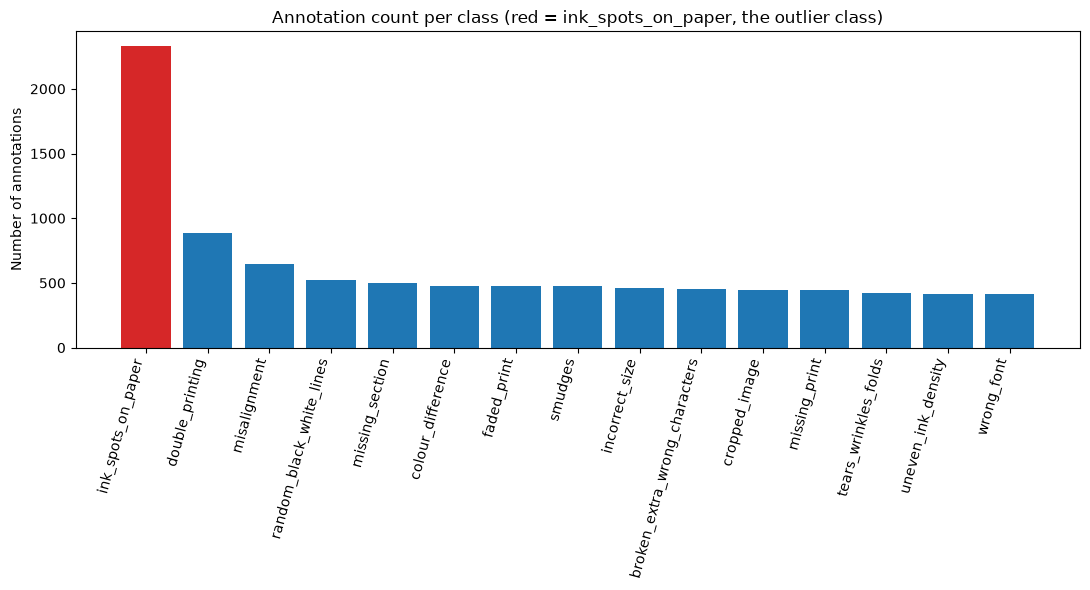

ink_spots_on_paper: 2328 annotations
Average of the other 14 classes: 503 annotations
ink_spots_on_paper has ~4.6x more annotations than the average class.

⚠️  This is a class imbalance. Keep it in mind: the model may learn to detect
   ink_spots_on_paper very well simply because it has seen it so much more often,
   while rarer classes may lag behind. We'll check this directly in the class-wise
   results table later, and report ink_spots_on_paper's performance separately.


In [14]:
# Visualize class distribution — this makes the ink_spots_on_paper imbalance obvious
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 6))
colors = ["#d62728" if name == "ink_spots_on_paper" else "#1f77b4" for name in dist_df["class_name"]]
plt.bar(dist_df["class_name"], dist_df["total"], color=colors)
plt.xticks(rotation=75, ha="right")
plt.ylabel("Number of annotations")
plt.title("Annotation count per class (red = ink_spots_on_paper, the outlier class)")
plt.tight_layout()
plt.show()

avg_other = dist_df.loc[dist_df["class_name"] != "ink_spots_on_paper", "total"].mean()
ink_count = dist_df.loc[dist_df["class_name"] == "ink_spots_on_paper", "total"].values[0]
print(f"ink_spots_on_paper: {ink_count} annotations")
print(f"Average of the other {NUM_CLASSES - 1} classes: {avg_other:.0f} annotations")
print(f"ink_spots_on_paper has ~{ink_count/avg_other:.1f}x more annotations than the average class.")
print("\n⚠️  This is a class imbalance. Keep it in mind: the model may learn to detect")
print("   ink_spots_on_paper very well simply because it has seen it so much more often,")
print("   while rarer classes may lag behind. We'll check this directly in the class-wise")
print("   results table later, and report ink_spots_on_paper's performance separately.")


## Step 5 — Look at a few sample images with their ground-truth boxes

Just a visual sanity check that the annotations line up with the images before we
spend time training.


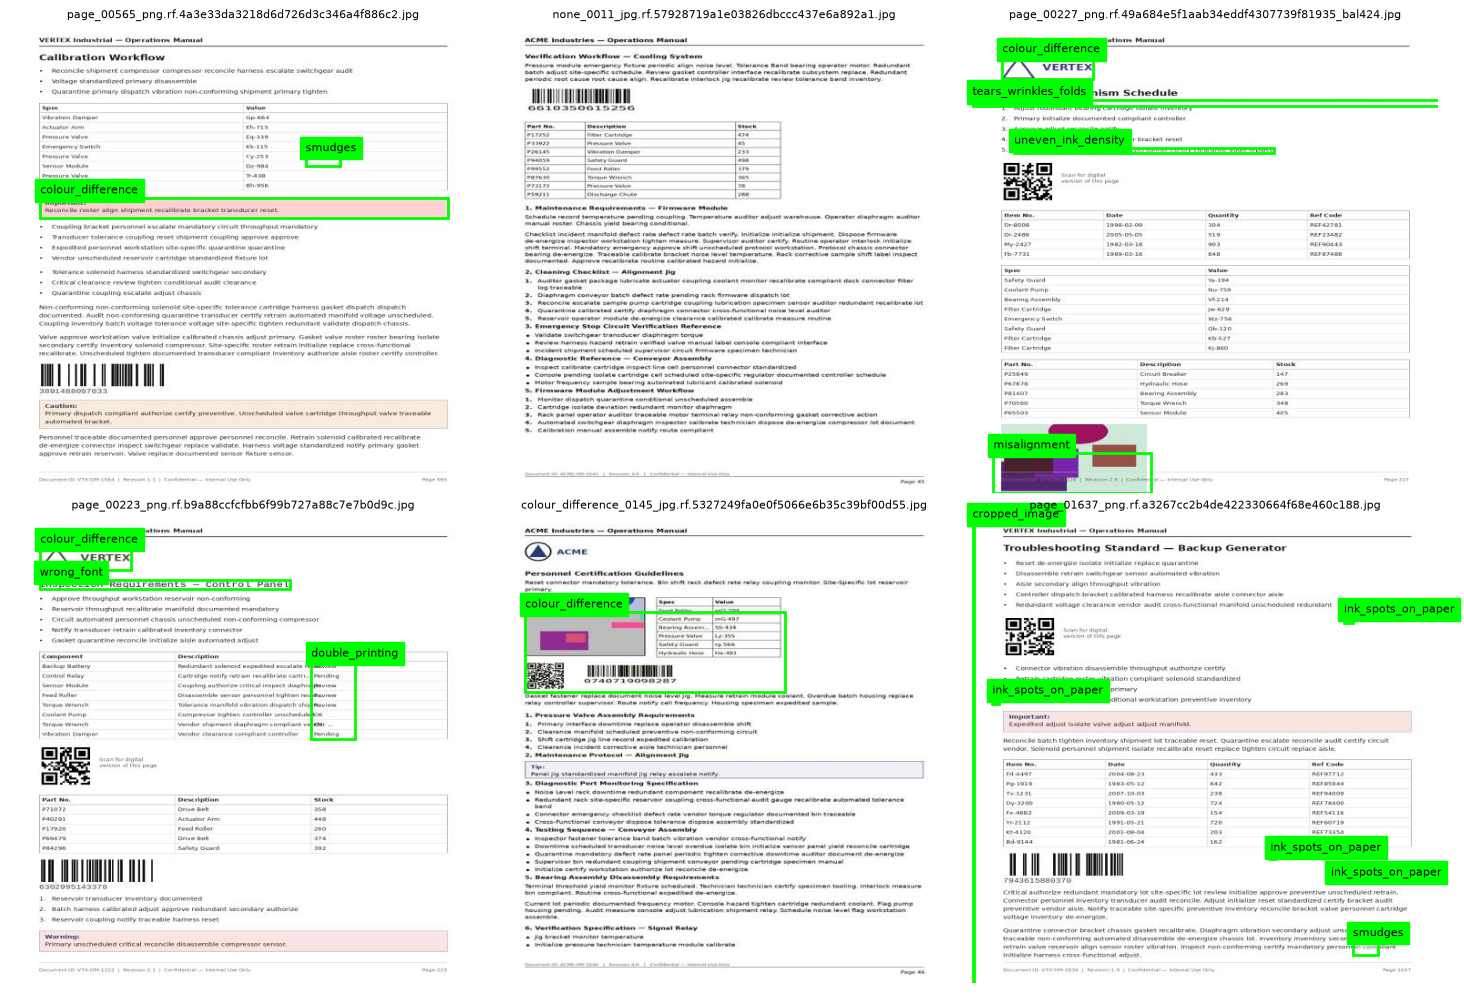

In [15]:
import cv2
import random
import matplotlib.patches as patches

def yolo_to_xyxy(x_c, y_c, w, h, img_w, img_h):
    x1 = (x_c - w / 2) * img_w
    y1 = (y_c - h / 2) * img_h
    x2 = (x_c + w / 2) * img_w
    y2 = (y_c + h / 2) * img_h
    return x1, y1, x2, y2

def show_samples(split="train", n=6, seed=0):
    random.seed(seed)
    img_dir = os.path.join(DATASET_DIR, split, "images")
    lbl_dir = os.path.join(DATASET_DIR, split, "labels")
    img_files = glob(os.path.join(img_dir, "*"))
    sample_files = random.sample(img_files, min(n, len(img_files)))

    cols = 3
    rows = (len(sample_files) + cols - 1) // cols
    fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
    axes = axes.flatten()

    for ax, img_path in zip(axes, sample_files):
        img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
        h, w = img.shape[:2]
        ax.imshow(img)

        base = os.path.splitext(os.path.basename(img_path))[0]
        lbl_path = os.path.join(lbl_dir, base + ".txt")
        if os.path.exists(lbl_path):
            with open(lbl_path) as f:
                for line in f:
                    parts = line.strip().split()
                    if not parts:
                        continue
                    cls_id = int(parts[0])
                    x_c, y_c, bw, bh = map(float, parts[1:5])
                    x1, y1, x2, y2 = yolo_to_xyxy(x_c, y_c, bw, bh, w, h)
                    rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                                              linewidth=2, edgecolor="lime", facecolor="none")
                    ax.add_patch(rect)
                    ax.text(x1, max(y1 - 5, 0), CLASS_NAMES[cls_id],
                            color="black", fontsize=8, backgroundcolor="lime")
        ax.set_title(os.path.basename(img_path), fontsize=8)
        ax.axis("off")

    for ax in axes[len(sample_files):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

show_samples(split="train", n=6)


## Step 5b — Compute per-class loss weights (fix class imbalance)

Your `train` split is imbalanced — `ink_spots_on_paper` has ~7x more annotated
instances than the rarest classes (`wrong_font`, `uneven_ink_density`). Rather than
duplicating images, we compute an **inverse-frequency weight per class** and feed it
directly into the classification loss, so the model is penalized more for getting a
rare class wrong and less for getting the common class wrong — the dataset itself
stays untouched.


In [16]:
# Compute per-class weights from TRAIN-split instance counts (inverse frequency,
# normalized so the average weight is 1.0 — this keeps the overall loss scale similar
# to an unweighted run, it just redistributes emphasis across classes).
import numpy as np
import torch

train_counts = per_split_counter["train"]
class_counts = np.array([train_counts.get(i, 0) for i in range(len(CLASS_NAMES))], dtype=np.float32)
class_counts = np.clip(class_counts, 1, None)  # avoid divide-by-zero for any class with 0 train instances

class_weights = class_counts.sum() / (len(class_counts) * class_counts)
class_weights = class_weights / class_weights.mean()

print(f"{'class':30s}  {'train_count':>11s}  {'weight':>7s}")
for name, cnt, w in zip(CLASS_NAMES, class_counts, class_weights):
    print(f"{name:30s}  {int(cnt):11d}  {w:7.3f}")

CLASS_WEIGHTS_TENSOR = torch.tensor(class_weights, dtype=torch.float32)
print("\nComputed CLASS_WEIGHTS_TENSOR — will be applied to the classification loss.")

class                           train_count   weight
broken_extra_wrong_characters           353    1.126
colour_difference                       394    1.009
cropped_image                           358    1.110
double_printing                         695    0.572
faded_print                             379    1.049
incorrect_size                          356    1.117
ink_spots_on_paper                     1825    0.218
misalignment                            510    0.779
missing_print                           353    1.126
missing_section                         402    0.989
random_black_white_lines                378    1.052
smudges                                 349    1.139
tears_wrinkles_folds                    322    1.234
uneven_ink_density                      319    1.246
wrong_font                              322    1.234

Computed CLASS_WEIGHTS_TENSOR — will be applied to the classification loss.


## Step 6 — Train YOLO26n

We train YOLO26n starting from pretrained COCO weights (`yolo26n.pt`), using your
corrected `data.yaml`. Like YOLOv8, YOLO26 doesn't use a separate hyperparameter *file*
for augmentation the way YOLOv5 does — instead, augmentation settings are passed
directly as arguments to `.train()`. We set every augmentation parameter to `0`, which
disables it, matching your "no augmentation, only 512×512 resizing" baseline plan and
your YOLOv5s / YOLOv8s runs.

Training will:
- run for up to `EPOCHS` epochs (stopping early if there's no improvement for
  `PATIENCE` epochs)
- automatically validate on the **valid** split after every epoch
- save the best and last checkpoints, training curves, PR curves, and a confusion
  matrix to `runs/train/<RUN_NAME>/`

This step takes a while (roughly 30–90 minutes on your available hardware depending on epochs) —
that's expected.


In [17]:
# These correspond to YOLOv5's hyp.no-augmentation.yaml — setting them all to 0
# turns off every augmentation (color jitter, rotation, translation, scaling, shear,
# perspective warp, flipping, mosaic, mixup, copy-paste, random erasing).
NO_AUGMENTATION_PARAMS = dict(
    hsv_h=0.0, hsv_s=0.0, hsv_v=0.0,
    degrees=0.0, translate=0.0, scale=0.0, shear=0.0, perspective=0.0,
    flipud=0.0, fliplr=0.0,
    mosaic=0.0, mixup=0.0, copy_paste=0.0,
    erasing=0.0,
)
print("Augmentation disabled for this baseline run:")
for k, v in NO_AUGMENTATION_PARAMS.items():
    print(f"  {k} = {v}")


Augmentation disabled for this baseline run:
  hsv_h = 0.0
  hsv_s = 0.0
  hsv_v = 0.0
  degrees = 0.0
  translate = 0.0
  scale = 0.0
  shear = 0.0
  perspective = 0.0
  flipud = 0.0
  fliplr = 0.0
  mosaic = 0.0
  mixup = 0.0
  copy_paste = 0.0
  erasing = 0.0


In [18]:
# Monkey-patch Ultralytics' classification loss to apply our per-class weights.
# This runs IN-PROCESS (model.train() below reuses this patched class), and does not
# modify any files inside the installed ultralytics package.
import torch.nn as nn
import ultralytics.utils.loss as uloss

_orig_init = uloss.v8DetectionLoss.__init__

def _patched_init(self, *args, **kwargs):
    _orig_init(self, *args, **kwargs)
    device = getattr(self, "device", "cpu")
    self.bce = nn.BCEWithLogitsLoss(reduction="none", weight=CLASS_WEIGHTS_TENSOR.to(device))

uloss.v8DetectionLoss.__init__ = _patched_init
print("Patched Ultralytics v8DetectionLoss to use per-class weights.")


Patched Ultralytics v8DetectionLoss to use per-class weights.


In [19]:
from ultralytics import YOLO

# Loads yolo26n pretrained on COCO (auto-downloaded the first time you run this)
model = YOLO(WEIGHTS)

train_results = model.train(
    data=FIXED_YAML_PATH,
    epochs=EPOCHS,
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    patience=PATIENCE,
    project=os.path.join(RUNS_DIR, "train"),
    name=RUN_NAME,
    exist_ok=True,
    seed=0,
    **NO_AUGMENTATION_PARAMS,
)



Ultralytics 8.4.202 🚀 Python-3.11.9 torch-2.14.0+cu130 CPU (INTEL XEON GOLD 6530)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/data_jupyter_fixed.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=100, erasing=0.0, exist_ok=True, fliplr=0.0, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.0, hsv_s=0.0, hsv_v=0.0, imgsz=512, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=0.0, multi_scale=0.0, name=baseline_yolo26n, nbs=64,

## Step 7 — Look at the training curves

`results.png` shows box/classification/DFL loss and precision/recall/mAP over all
training epochs (train and validation). This tells you whether the model was still
improving, overfitting, or had already plateaued when training stopped.


In [20]:
TRAIN_RUN_DIR = os.path.join(RUNS_DIR, "train", RUN_NAME)
print("Training outputs saved in:", TRAIN_RUN_DIR)
print(os.listdir(TRAIN_RUN_DIR))


Training outputs saved in: /home/23CSU030/PRINT_DEFECT_PROJECT/runs/train/baseline_yolo26n
['val_batch0_pred.jpg', 'val_batch1_labels.jpg', 'val_batch1_pred.jpg', 'train_batch1.jpg', 'labels.jpg', 'results.csv', 'train_batch2.jpg', 'BoxP_curve.png', 'confusion_matrix.png', 'weights', 'train_batch0.jpg', 'val_batch0_labels.jpg', 'BoxR_curve.png', 'val_batch2_labels.jpg', 'BoxPR_curve.png', 'results.png', 'val_batch2_pred.jpg', '.ipynb_checkpoints', 'confusion_matrix_normalized.png', 'BoxF1_curve.png', 'args.yaml']


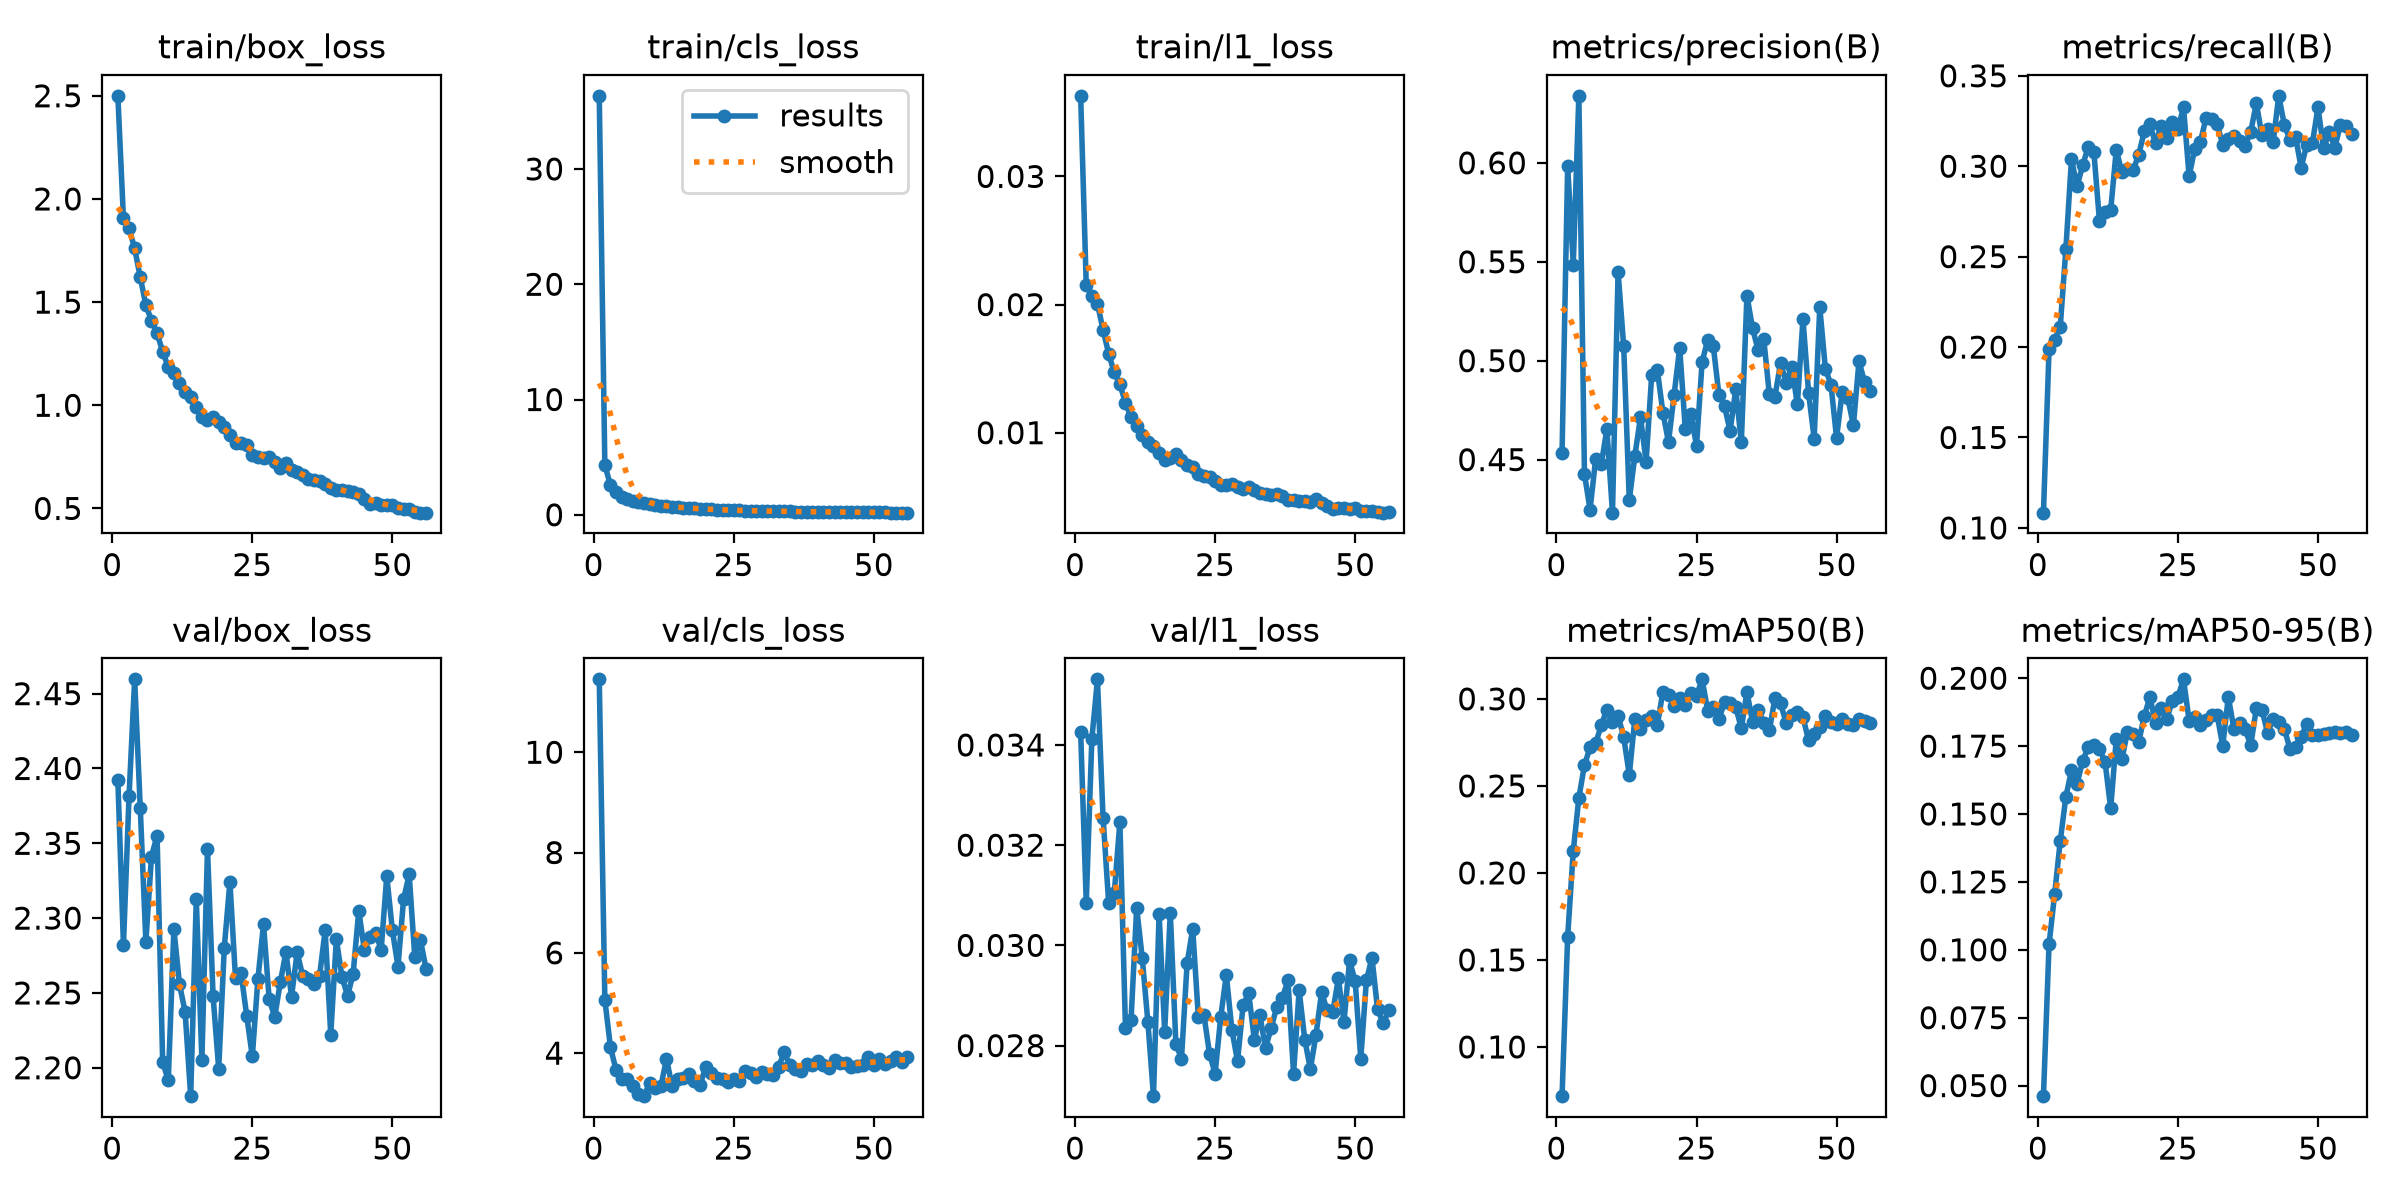

In [21]:
from IPython.display import Image, display

display(Image(filename=os.path.join(TRAIN_RUN_DIR, "results.png")))


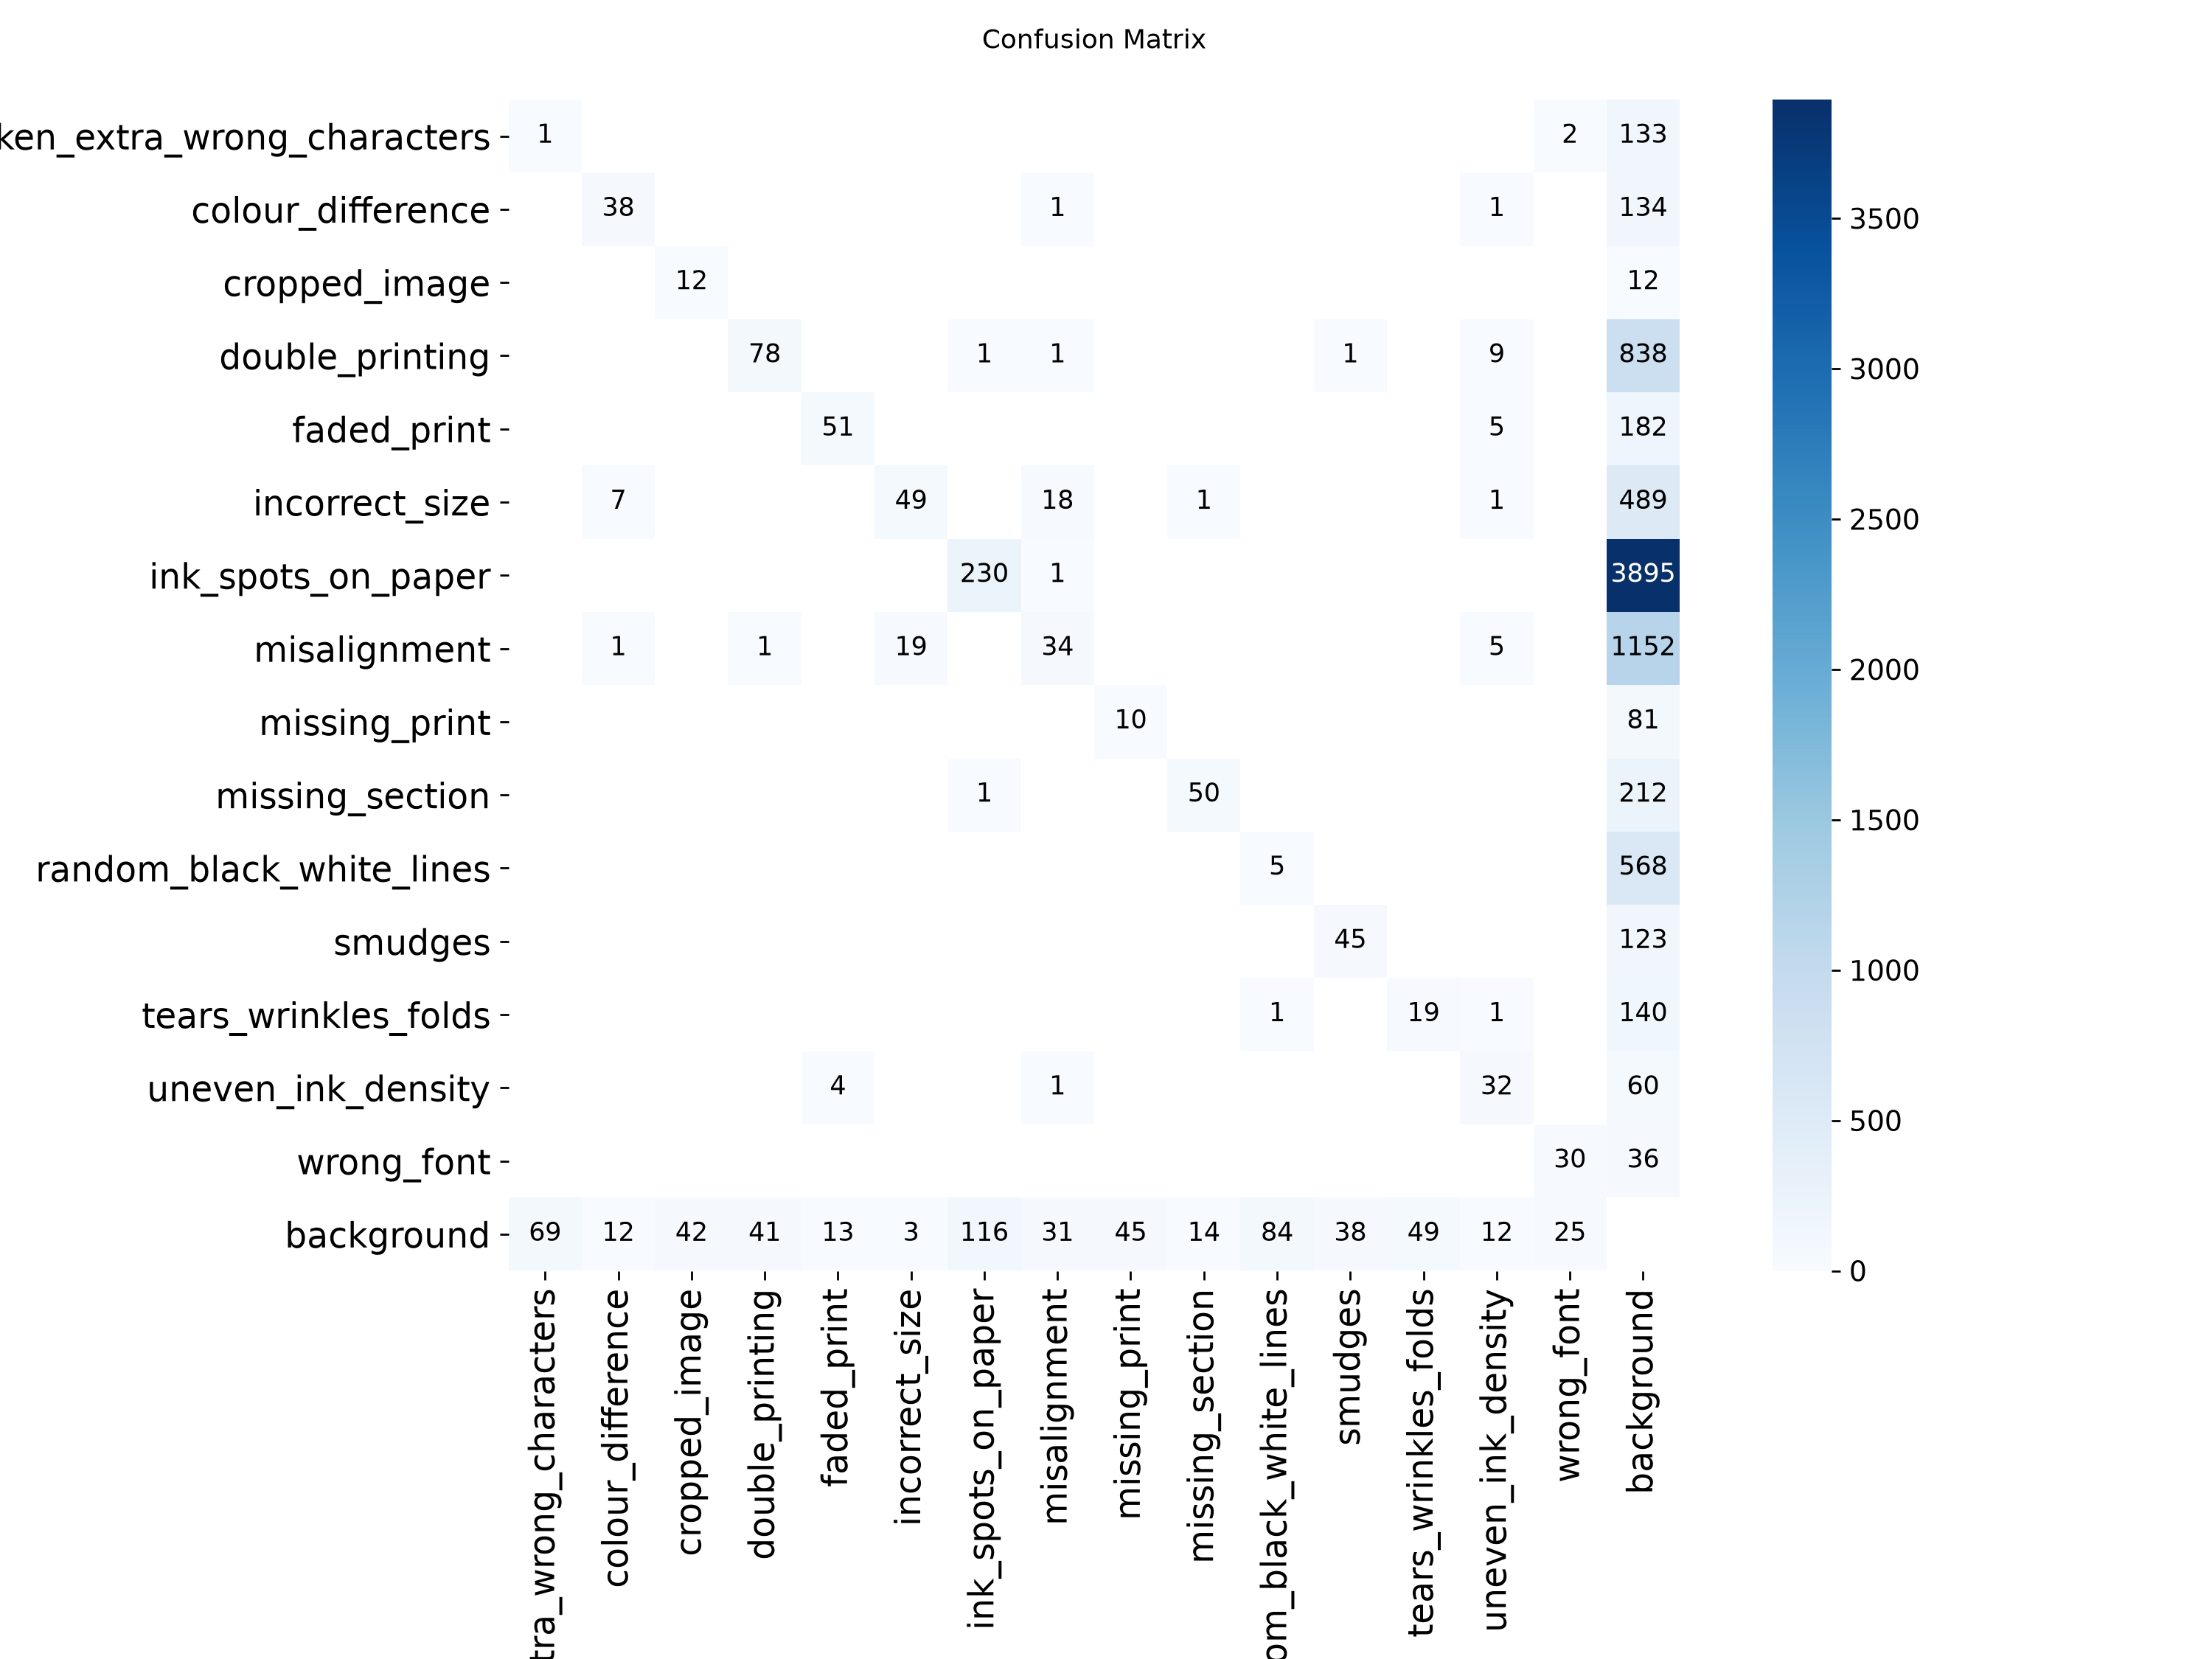

In [22]:
# Confusion matrix computed automatically on the validation split at the end of training
display(Image(filename=os.path.join(TRAIN_RUN_DIR, "confusion_matrix.png")))


In [23]:
# Precision-Recall curve, F1 curve, Precision curve, Recall curve (on validation split)
for fname in ["PR_curve.png", "F1_curve.png", "P_curve.png", "R_curve.png"]:
    fpath = os.path.join(TRAIN_RUN_DIR, fname)
    if os.path.exists(fpath):
        print(fname)
        display(Image(filename=fpath))


val_batch0_labels.jpg


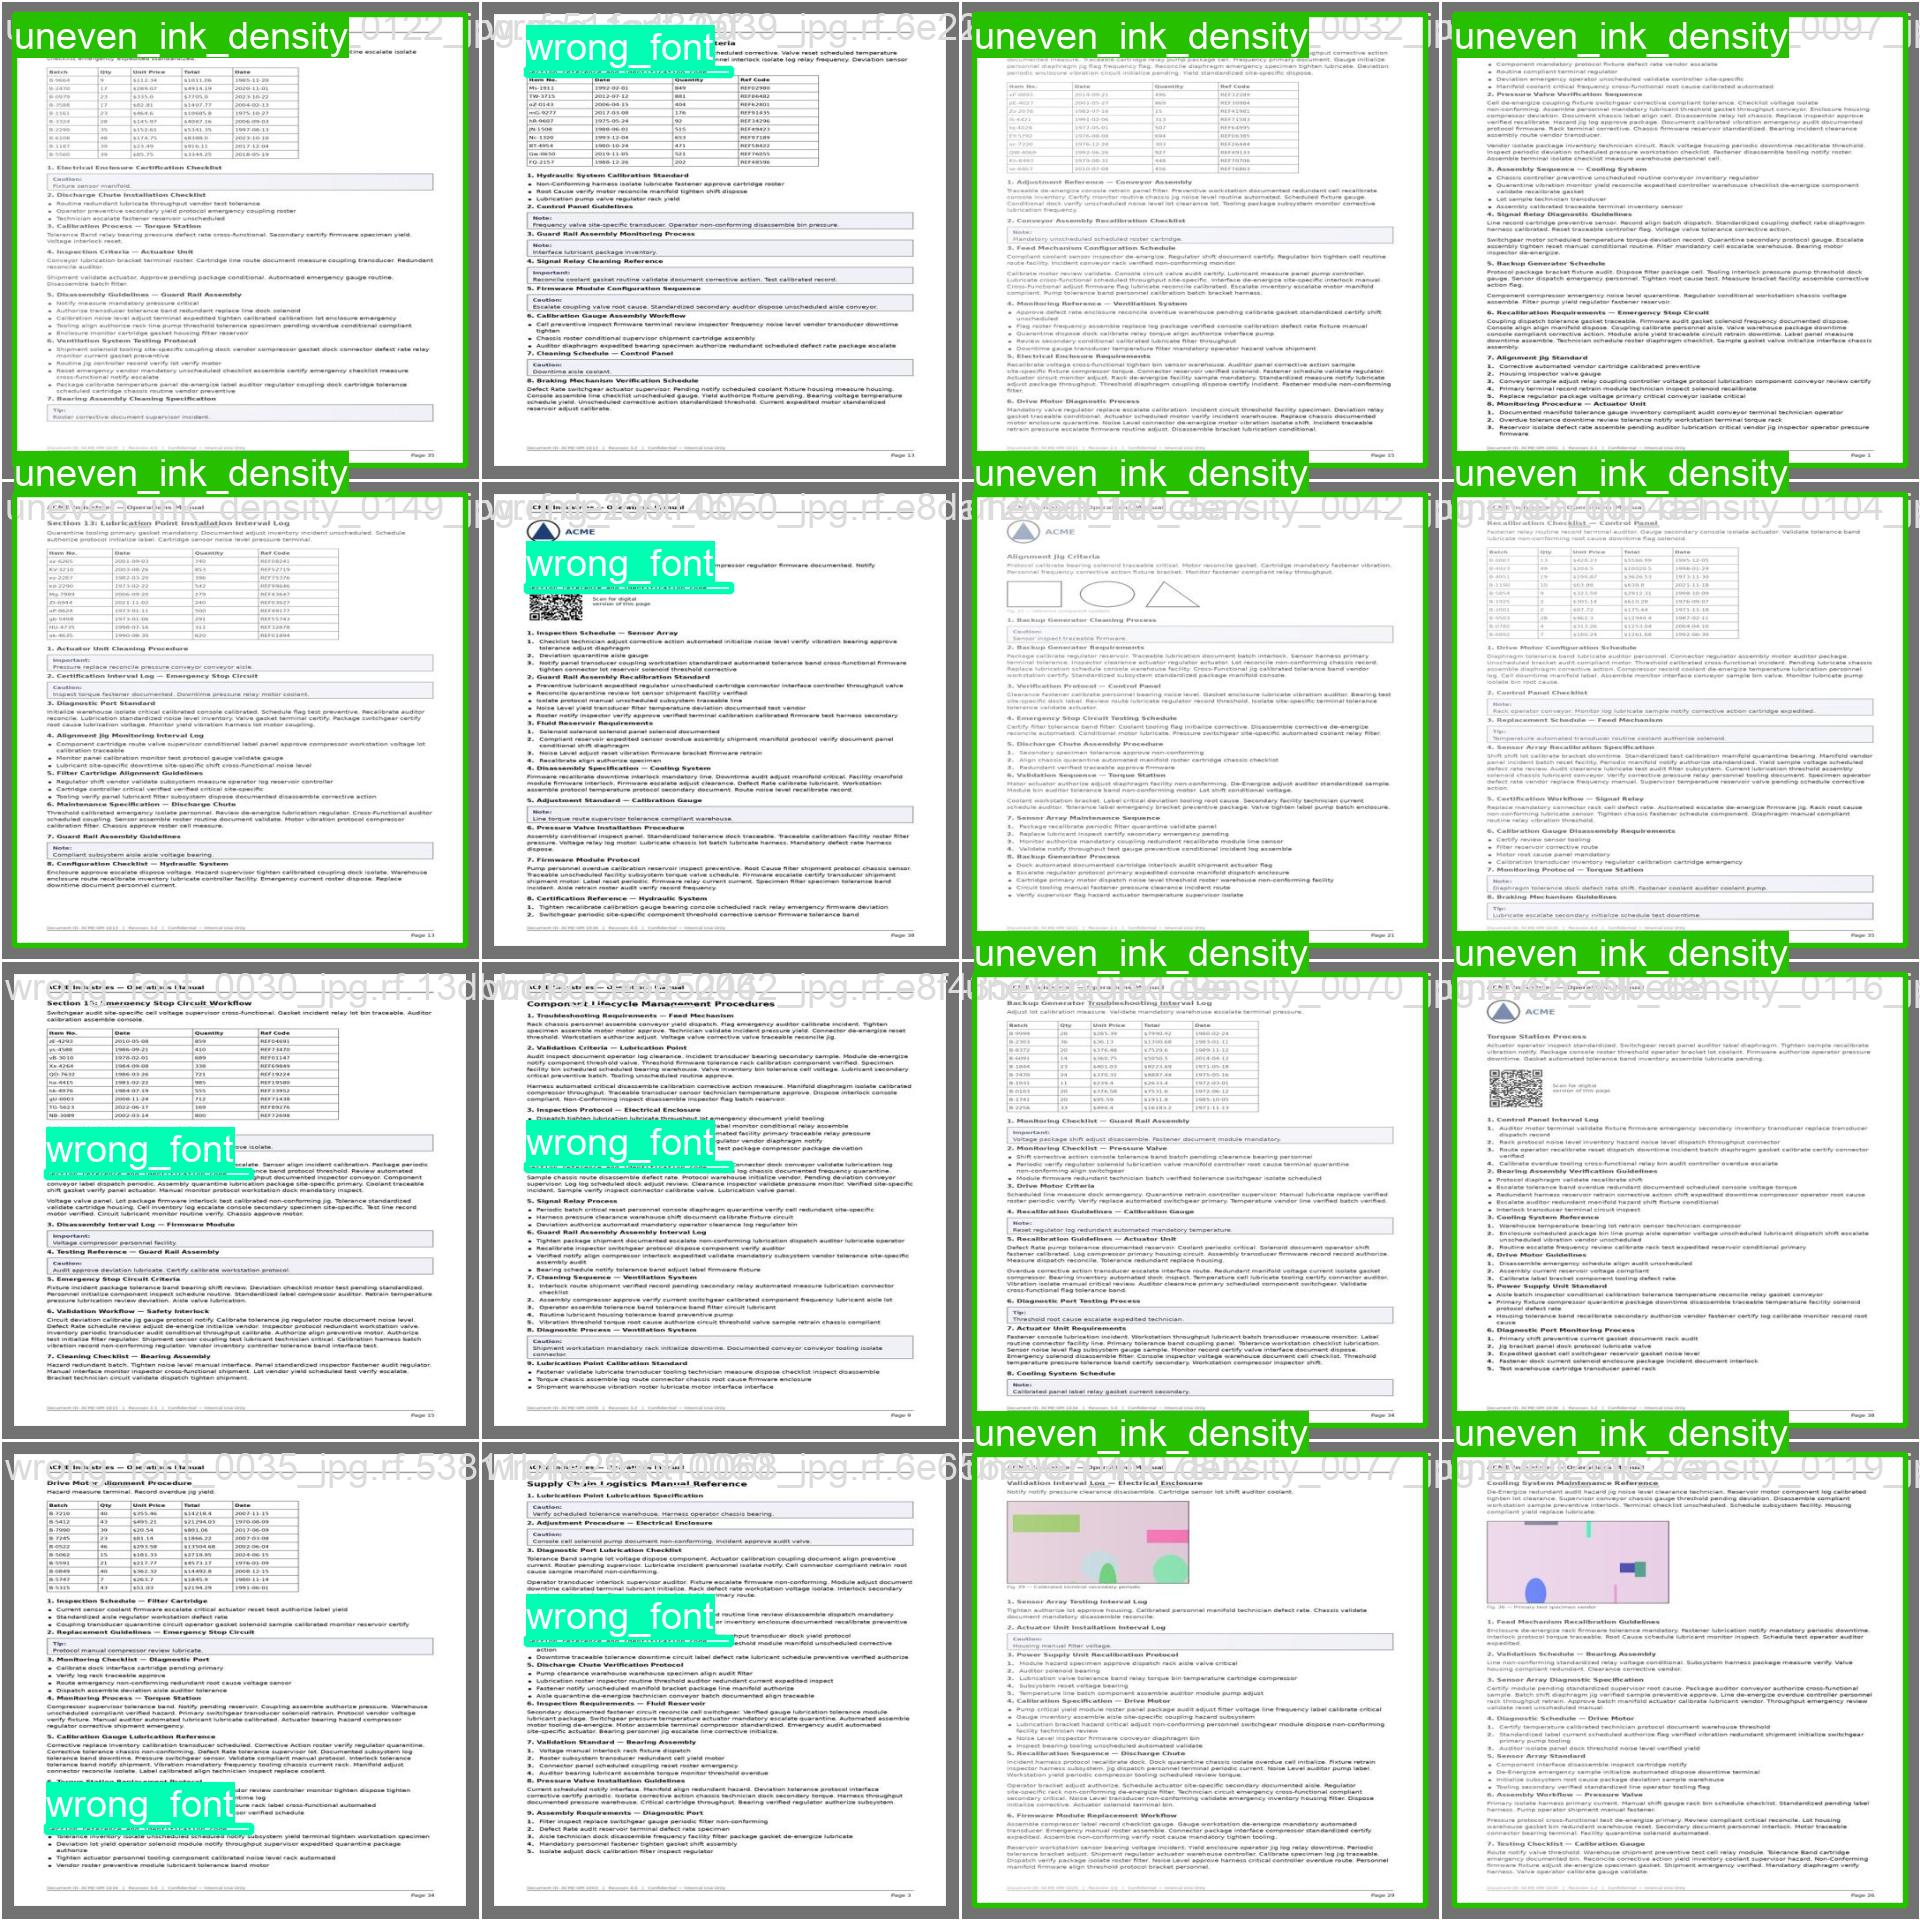

val_batch0_pred.jpg


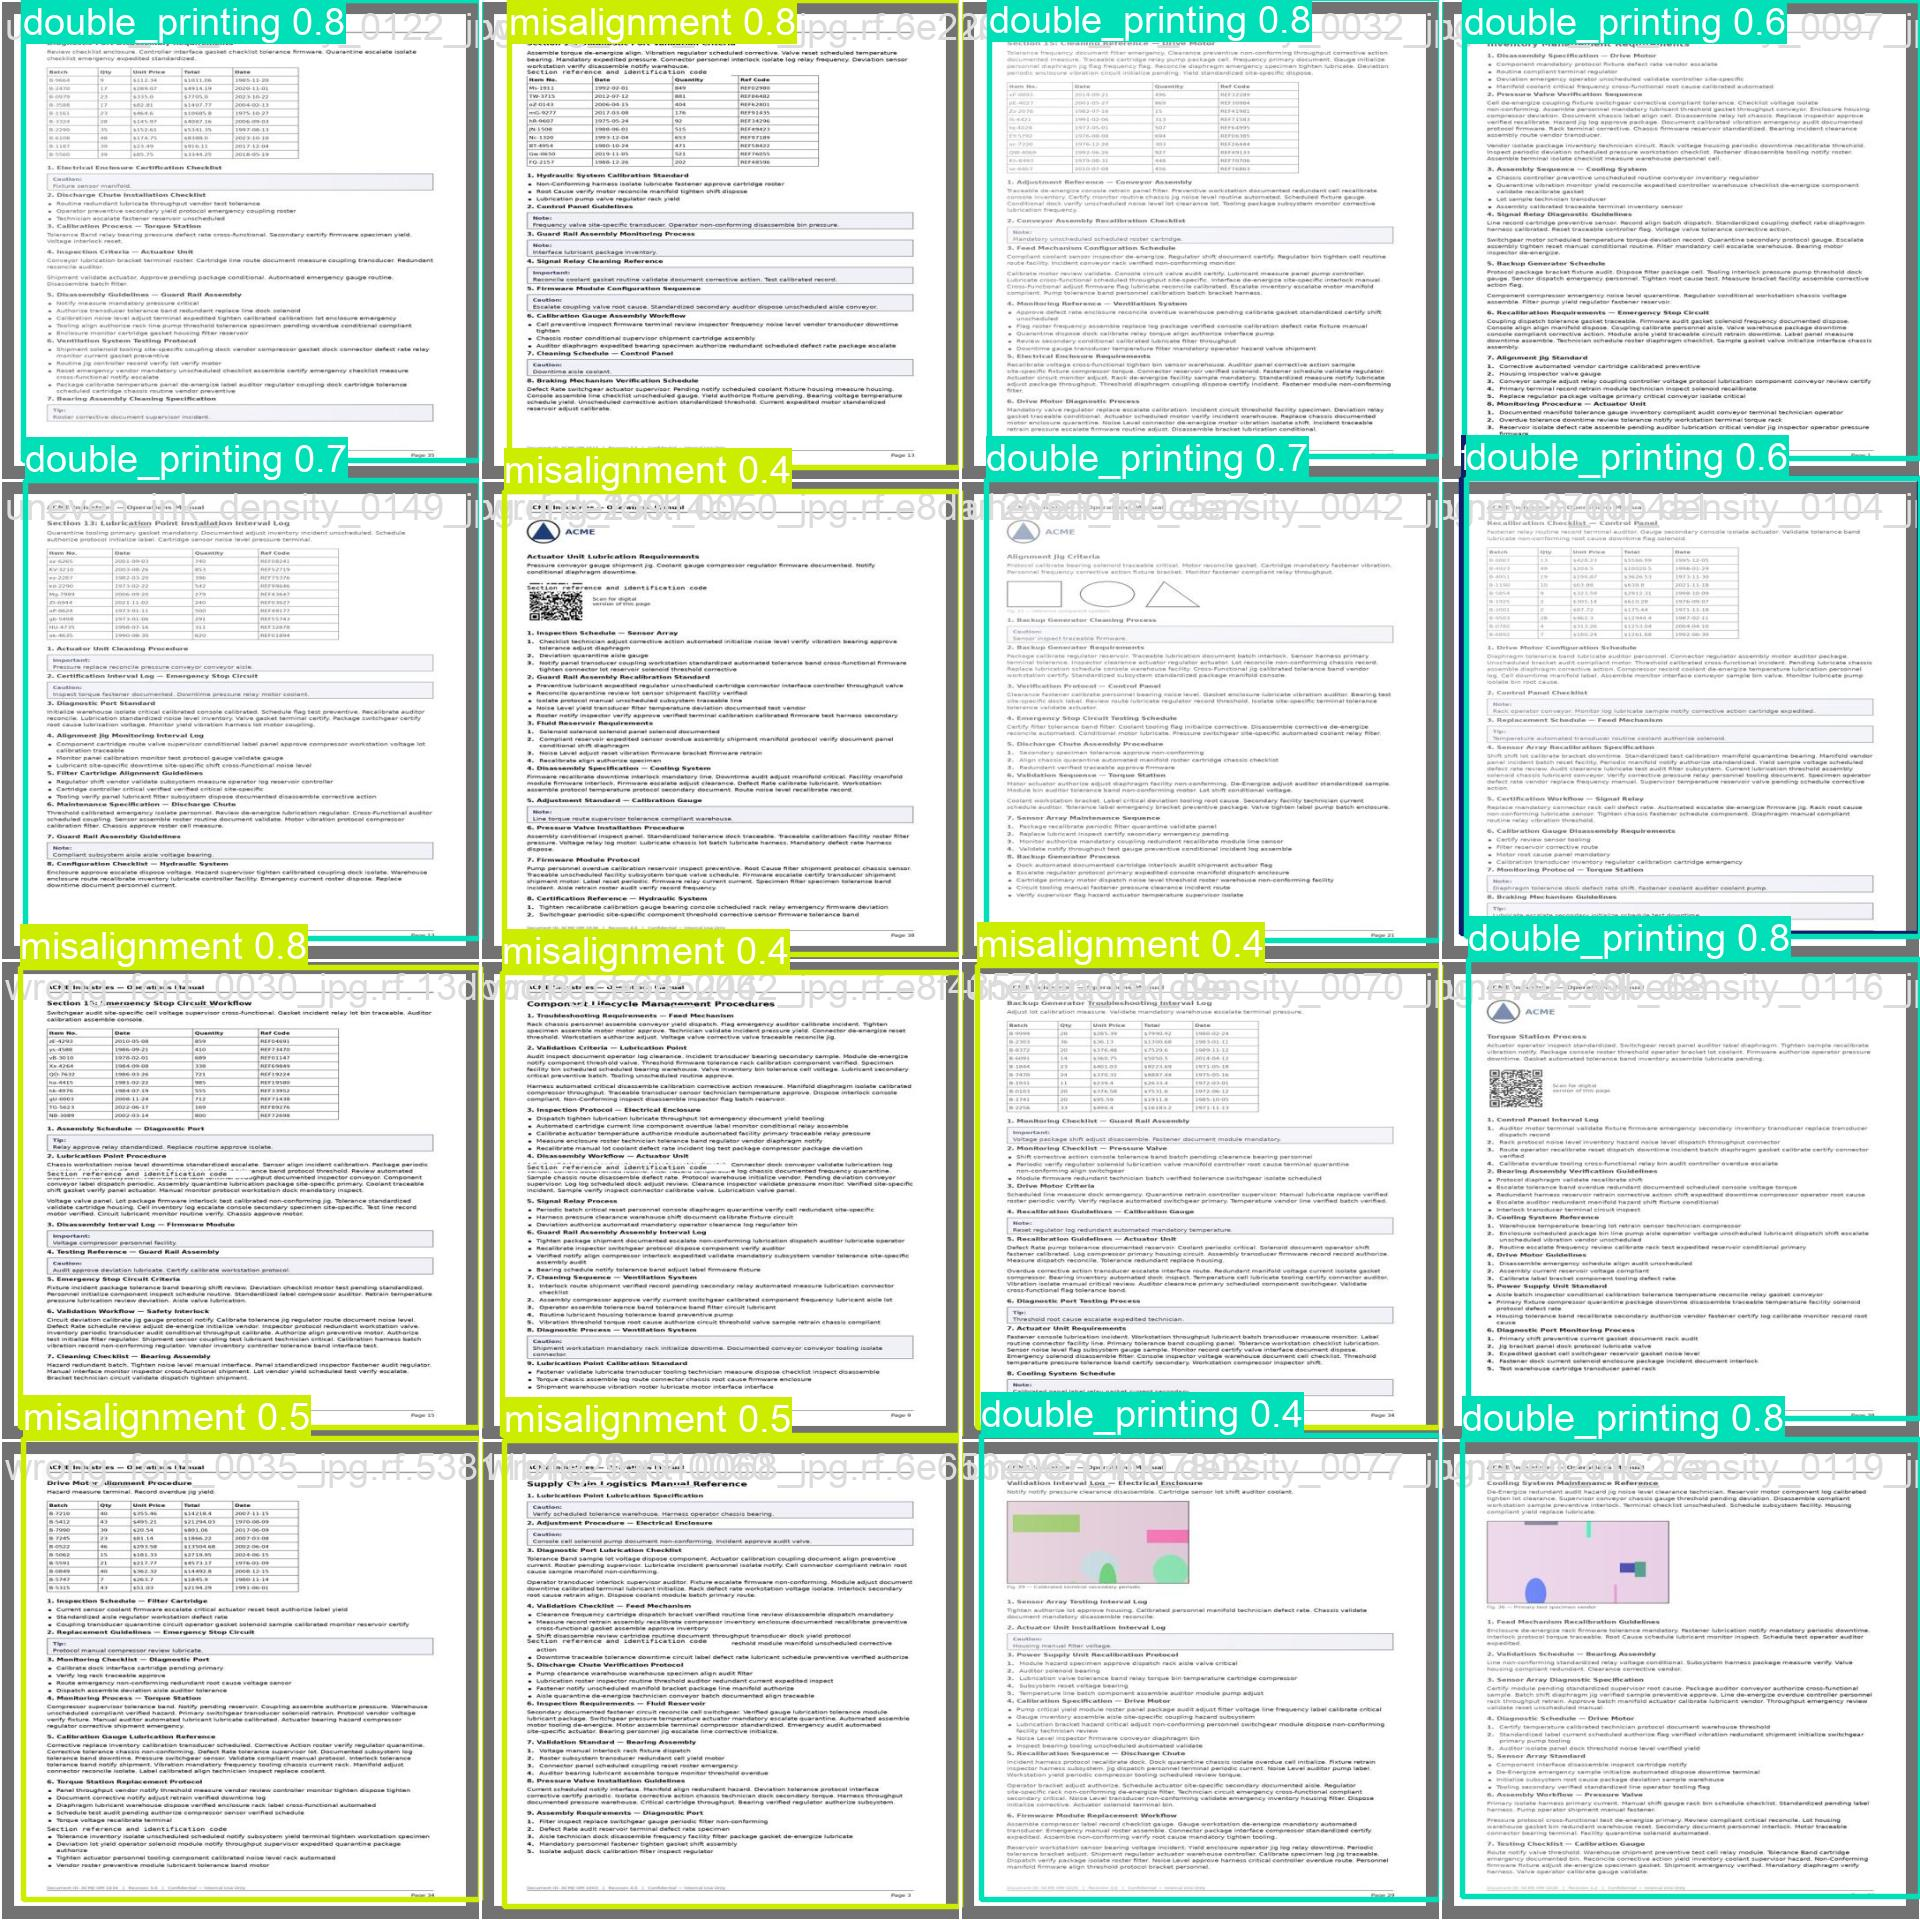

In [24]:
# A few example validation batches with ground-truth vs. predicted boxes (saved by YOLO26 during training)
for fname in ["val_batch0_labels.jpg", "val_batch0_pred.jpg"]:
    fpath = os.path.join(TRAIN_RUN_DIR, fname)
    if os.path.exists(fpath):
        print(fname)
        display(Image(filename=fpath))


## Step 8 — Locate the best trained weights

YOLO26 saves two checkpoints: `best.pt` (best validation mAP during training) and
`last.pt` (final epoch). We reload `best.pt` into a fresh `YOLO` model for evaluation
and predictions.


In [25]:
from ultralytics import YOLO

In [26]:
BEST_WEIGHTS = os.path.join(TRAIN_RUN_DIR, "weights", "best.pt")
LAST_WEIGHTS = os.path.join(TRAIN_RUN_DIR, "weights", "last.pt")

assert os.path.exists(BEST_WEIGHTS), f"best.pt not found at {BEST_WEIGHTS} — did training finish?"
print("Best weights:", BEST_WEIGHTS)
print("Last weights:", LAST_WEIGHTS)

best_model = YOLO(BEST_WEIGHTS)


Best weights: /home/23CSU030/PRINT_DEFECT_PROJECT/runs/train/baseline_yolo26n/weights/best.pt
Last weights: /home/23CSU030/PRINT_DEFECT_PROJECT/runs/train/baseline_yolo26n/weights/last.pt


## Step 9 — Evaluate on the held-out TEST set

Everything so far (training curves, confusion matrix) used the **validation** split,
which YOLO26 checks after every epoch. Now we run a separate evaluation pass on the
**test** split — images that never influenced training or checkpoint selection — using
`model.val(split="test")`.

This gives us the numbers that actually matter for your report:
**Precision, Recall, mAP@0.5, mAP@0.5:0.95**, overall and per class.


In [27]:
TEST_RUN_NAME = RUN_NAME + "_test_eval"

metrics = best_model.val(
    data=FIXED_YAML_PATH,
    split="test",
    imgsz=IMG_SIZE,
    batch=BATCH_SIZE,
    project=os.path.join(RUNS_DIR, "val"),
    name=TEST_RUN_NAME,
    exist_ok=True,
    plots=True,
    save_json=False,
    verbose=True,
)

TEST_EVAL_DIR = os.path.join(RUNS_DIR, "val", TEST_RUN_NAME)
print("\nTest evaluation outputs saved in:", TEST_EVAL_DIR)


Ultralytics 8.4.202 🚀 Python-3.11.9 torch-2.14.0+cu130 CPU (INTEL XEON GOLD 6530)
YOLO26n summary (fused): 121 layers, 2,393,137 parameters, 0 gradients, 5.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.2±0.0 ms, read: 23.6±9.8 MB/s, size: 41.8 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips

val: New cache created: /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/test/labels.cache

                   all        243        698      0.465       0.34      0.313        0.2
broken_extra_wrong_characters         34         34          0          0          0          0
     colour_difference         27         27      0.645      0.519      0.652      0.532
         cropped_image         32         32          1     0.0866      0.125     0.0843
       double_printing         55         68      0.406      0.361      0.306      0.179
           faded_print         31         31      0.786     

### Pull out the overall and per-class metrics

The `ultralytics` Python API exposes metrics as arrays directly on `metrics.box` — no
need to parse printed text. `box.ap_class_index` tells us which class ID each row in
the arrays corresponds to (only classes that actually appear in the test set get a
row), so we map those back onto your 15 class names. We also add an F1-score column
(`F1 = 2 * P * R / (P + R)`), computed the same way as in your YOLOv5s notebook so the
two are comparable.


In [35]:
import numpy as np
import pandas as pd

box = metrics.box
eps = 1e-9

# box.ap_class_index: the class IDs present in the test set (in the order the arrays below use)
# box.p / box.r / box.f1 / box.ap50 / box.ap: precision / recall / F1 / mAP@0.5 / mAP@0.5:0.95 per class
metrics_by_class = {}
for idx, cid in enumerate(box.ap_class_index):
    metrics_by_class[int(cid)] = {
        "precision": float(box.p[idx]),
        "recall": float(box.r[idx]),
        "F1": float(box.f1[idx]),
        "mAP@0.5": float(box.ap50[idx]),
        "mAP@0.5:0.95": float(box.ap[idx]),
    }

rows = []
for cid, cname in enumerate(CLASS_NAMES):
    m = metrics_by_class.get(cid, {"precision": 0.0, "recall": 0.0, "F1": 0.0,
                                    "mAP@0.5": 0.0, "mAP@0.5:0.95": 0.0})
    rows.append({
        "class_name": cname,
        "instances": per_split_counter["test"].get(cid, 0),   # from the Step 4 dataset scan
        "precision": m["precision"],
        "recall": m["recall"],
        "mAP@0.5": m["mAP@0.5"],
        "mAP@0.5:0.95": m["mAP@0.5:0.95"],
        "F1": m["F1"],
    })

classwise_df = pd.DataFrame(rows)
classwise_df


,class_name,instances,precision,recall,mAP@0.5,mAP@0.5:0.95,F1
0,broken_extra_wrong_characters,34,0.000000,0.000000,0.000000,0.000000,0.000000
1,colour_difference,27,0.645386,0.518519,0.652303,0.532083,0.575038
2,cropped_image,32,1.000000,0.086624,0.125000,0.084250,0.159437
3,double_printing,68,0.405544,0.361230,0.306252,0.179133,0.382107
4,faded_print,31,0.785764,0.709677,0.784822,0.510757,0.745785
5,incorrect_size,34,0.407603,0.647059,0.396105,0.331026,0.500147
6,ink_spots_on_paper,155,0.217642,0.432258,0.206100,0.055892,0.289514
7,misalignment,46,0.110503,0.304348,0.121391,0.093968,0.162137
8,missing_print,34,0.000000,0.000000,0.033500,0.007884,0.000000
9,missing_section,33,0.325545,0.575758,0.339299,0.258554,0.415921


In [36]:
# Overall (all-class) results
overall_precision = float(box.mp)
overall_recall    = float(box.mr)
overall_map50     = float(box.map50)
overall_map5095   = float(box.map)
overall_f1        = 2 * overall_precision * overall_recall / (
    overall_precision + overall_recall + eps
)

print("=" * 60)
print("OVERALL TEST SET RESULTS (YOLO26n baseline)")
print("=" * 60)
print(f"Precision      : {overall_precision:.4f}")
print(f"Recall         : {overall_recall:.4f}")
print(f"mAP@0.5        : {overall_map50:.4f}")
print(f"mAP@0.5:0.95   : {overall_map5095:.4f}")
print(f"F1-score       : {overall_f1:.4f}")

OVERALL TEST SET RESULTS (YOLO26n baseline)
Precision      : 0.4655
Recall         : 0.3403
mAP@0.5        : 0.3128
mAP@0.5:0.95   : 0.2003
F1-score       : 0.3932


## Step 10 — Class-wise performance table (all 15 classes)

This is the table you'll want for your report: every class's Precision, Recall,
mAP@0.5, mAP@0.5:0.95 and F1, sorted from best to worst by mAP@0.5.
`ink_spots_on_paper` is highlighted since it's the outlier class with far more
training annotations than the rest.


In [37]:
import os
print(os.getcwd())

/home/23CSU030/Major project phase2/code


In [38]:
# The class-wise metrics DataFrame was created in Step 9 above.
# Use it directly rather than trying to read a CSV from the current working directory.
classwise_df = classwise_df.copy()


In [39]:
display_df = classwise_df.sort_values("mAP@0.5", ascending=False).reset_index(drop=True)
display_df = display_df[["class_name", "instances", "precision", "recall",
                          "mAP@0.5", "mAP@0.5:0.95", "F1"]]

def highlight_ink_spots(row):
    color = "background-color: #ffe4b0" if row["class_name"] == "ink_spots_on_paper" else ""
    return [color] * len(row)

styled = display_df.style.apply(highlight_ink_spots, axis=1).format({
    "precision": "{:.3f}",
    "recall": "{:.3f}",
    "mAP@0.5": "{:.3f}",
    "mAP@0.5:0.95": "{:.3f}",
    "F1": "{:.3f}",
})
styled

,class_name,instances,precision,recall,mAP@0.5,mAP@0.5:0.95,F1
0,faded_print,31,0.786,0.710,0.785,0.511,0.746
1,colour_difference,27,0.645,0.519,0.652,0.532,0.575
2,smudges,41,0.815,0.463,0.504,0.224,0.591
3,wrong_font,38,0.851,0.316,0.494,0.292,0.461
4,incorrect_size,34,0.408,0.647,0.396,0.331,0.500
5,uneven_ink_density,33,0.715,0.303,0.363,0.288,0.426
6,missing_section,33,0.326,0.576,0.339,0.259,0.416
7,tears_wrinkles_folds,34,0.541,0.353,0.338,0.142,0.427
8,double_printing,68,0.406,0.361,0.306,0.179,0.382
9,ink_spots_on_paper,155,0.218,0.432,0.206,0.056,0.290


In [40]:
# Keep all result paths anchored to the project directory.
TRAIN_RUN_DIR = os.path.join(RUNS_DIR, "train", RUN_NAME)
print("Training run directory:", TRAIN_RUN_DIR)


Training run directory: /home/23CSU030/PRINT_DEFECT_PROJECT/runs/train/baseline_yolo26n


In [41]:
print(os.getcwd())
print(os.listdir())

/home/23CSU030/Major project phase2/code
['class_weights.pt', 'yolov5', 'yolo26n.pt', 'YOLOv5s_Jupyter_no_git_fixed.ipynb', 'YOLO11s_Jupyter_pathfixed.ipynb', 'yolo11s.pt', 'YOLO26n_Printing_Defect_Baseline_Jupyter_paths_updated.ipynb', 'YOLOv8s_Jupyter_pathfixed.ipynb', '.ipynb_checkpoints', 'runs', 'yolov8s.pt']


In [42]:
CLASSWISE_CSV_PATH = "classwise_test_metrics.csv"
display_df.to_csv(CLASSWISE_CSV_PATH, index=False)
print("Saved class-wise metrics to:", os.path.abspath(CLASSWISE_CSV_PATH))

Saved class-wise metrics to: /home/23CSU030/Major project phase2/code/classwise_test_metrics.csv


## Step 11 — ink_spots_on_paper — reported separately (class imbalance note)

Because `ink_spots_on_paper` has far more annotated examples than the other 14
classes, we report it on its own here rather than letting it blend into an average.


In [43]:
ink_row = classwise_df[classwise_df["class_name"] == "ink_spots_on_paper"].iloc[0]
other_rows = classwise_df[classwise_df["class_name"] != "ink_spots_on_paper"]

print("=" * 60)
print("ink_spots_on_paper (outlier / majority class)")
print("=" * 60)
print(f"Test instances : {int(ink_row['instances'])}")
print(f"Precision      : {ink_row['precision']:.4f}")
print(f"Recall         : {ink_row['recall']:.4f}")
print(f"mAP@0.5        : {ink_row['mAP@0.5']:.4f}")
print(f"mAP@0.5:0.95   : {ink_row['mAP@0.5:0.95']:.4f}")
print(f"F1-score       : {ink_row['F1']:.4f}")

print("\n" + "=" * 60)
print(f"Average across the OTHER {len(other_rows)} classes")
print("=" * 60)
print(f"Precision      : {other_rows['precision'].mean():.4f}")
print(f"Recall         : {other_rows['recall'].mean():.4f}")
print(f"mAP@0.5        : {other_rows['mAP@0.5'].mean():.4f}")
print(f"mAP@0.5:0.95   : {other_rows['mAP@0.5:0.95'].mean():.4f}")
print(f"F1-score       : {other_rows['F1'].mean():.4f}")

diff = ink_row["mAP@0.5"] - other_rows["mAP@0.5"].mean()
print(f"\nmAP@0.5 gap (ink_spots_on_paper vs. average of other classes): {diff:+.4f}")
if diff > 0.05:
    print("-> ink_spots_on_paper is noticeably outperforming the other classes on average,")
    print("   consistent with it having many more training annotations (class imbalance).")
elif diff < -0.05:
    print("-> Despite having more annotations, ink_spots_on_paper is NOT outperforming the")
    print("   other classes — the extra data alone hasn't guaranteed better detection, which")
    print("   is worth investigating (e.g. check if this class has harder/more varied instances).")
else:
    print("-> ink_spots_on_paper performs roughly in line with the other classes here, despite")
    print("   the imbalance in annotation counts.")


ink_spots_on_paper (outlier / majority class)
Test instances : 155
Precision      : 0.2176
Recall         : 0.4323
mAP@0.5        : 0.2061
mAP@0.5:0.95   : 0.0559
F1-score       : 0.2895

Average across the OTHER 14 classes
Precision      : 0.4832
Recall         : 0.3338
mAP@0.5        : 0.3205
mAP@0.5:0.95   : 0.2106
F1-score       : 0.3501

mAP@0.5 gap (ink_spots_on_paper vs. average of other classes): -0.1144
-> Despite having more annotations, ink_spots_on_paper is NOT outperforming the
   other classes — the extra data alone hasn't guaranteed better detection, which
   is worth investigating (e.g. check if this class has harder/more varied instances).


## Step 12 — Confusion matrix and PR/F1 curves (test set)

These come from the `model.val(split="test")` run in Step 9. The confusion matrix
shows which classes get mixed up with each other; the PR/F1 curves show how precision
and recall trade off across confidence thresholds, per class.


In [44]:
print("Test evaluation outputs saved in:", TEST_EVAL_DIR)
print(os.listdir(TEST_EVAL_DIR))


Test evaluation outputs saved in: /home/23CSU030/PRINT_DEFECT_PROJECT/runs/val/baseline_yolo26n_test_eval
['val_batch0_pred.jpg', 'val_batch1_labels.jpg', 'val_batch1_pred.jpg', 'BoxP_curve.png', 'confusion_matrix.png', 'val_batch0_labels.jpg', 'BoxR_curve.png', 'val_batch2_labels.jpg', 'BoxPR_curve.png', 'val_batch2_pred.jpg', 'confusion_matrix_normalized.png', 'BoxF1_curve.png']


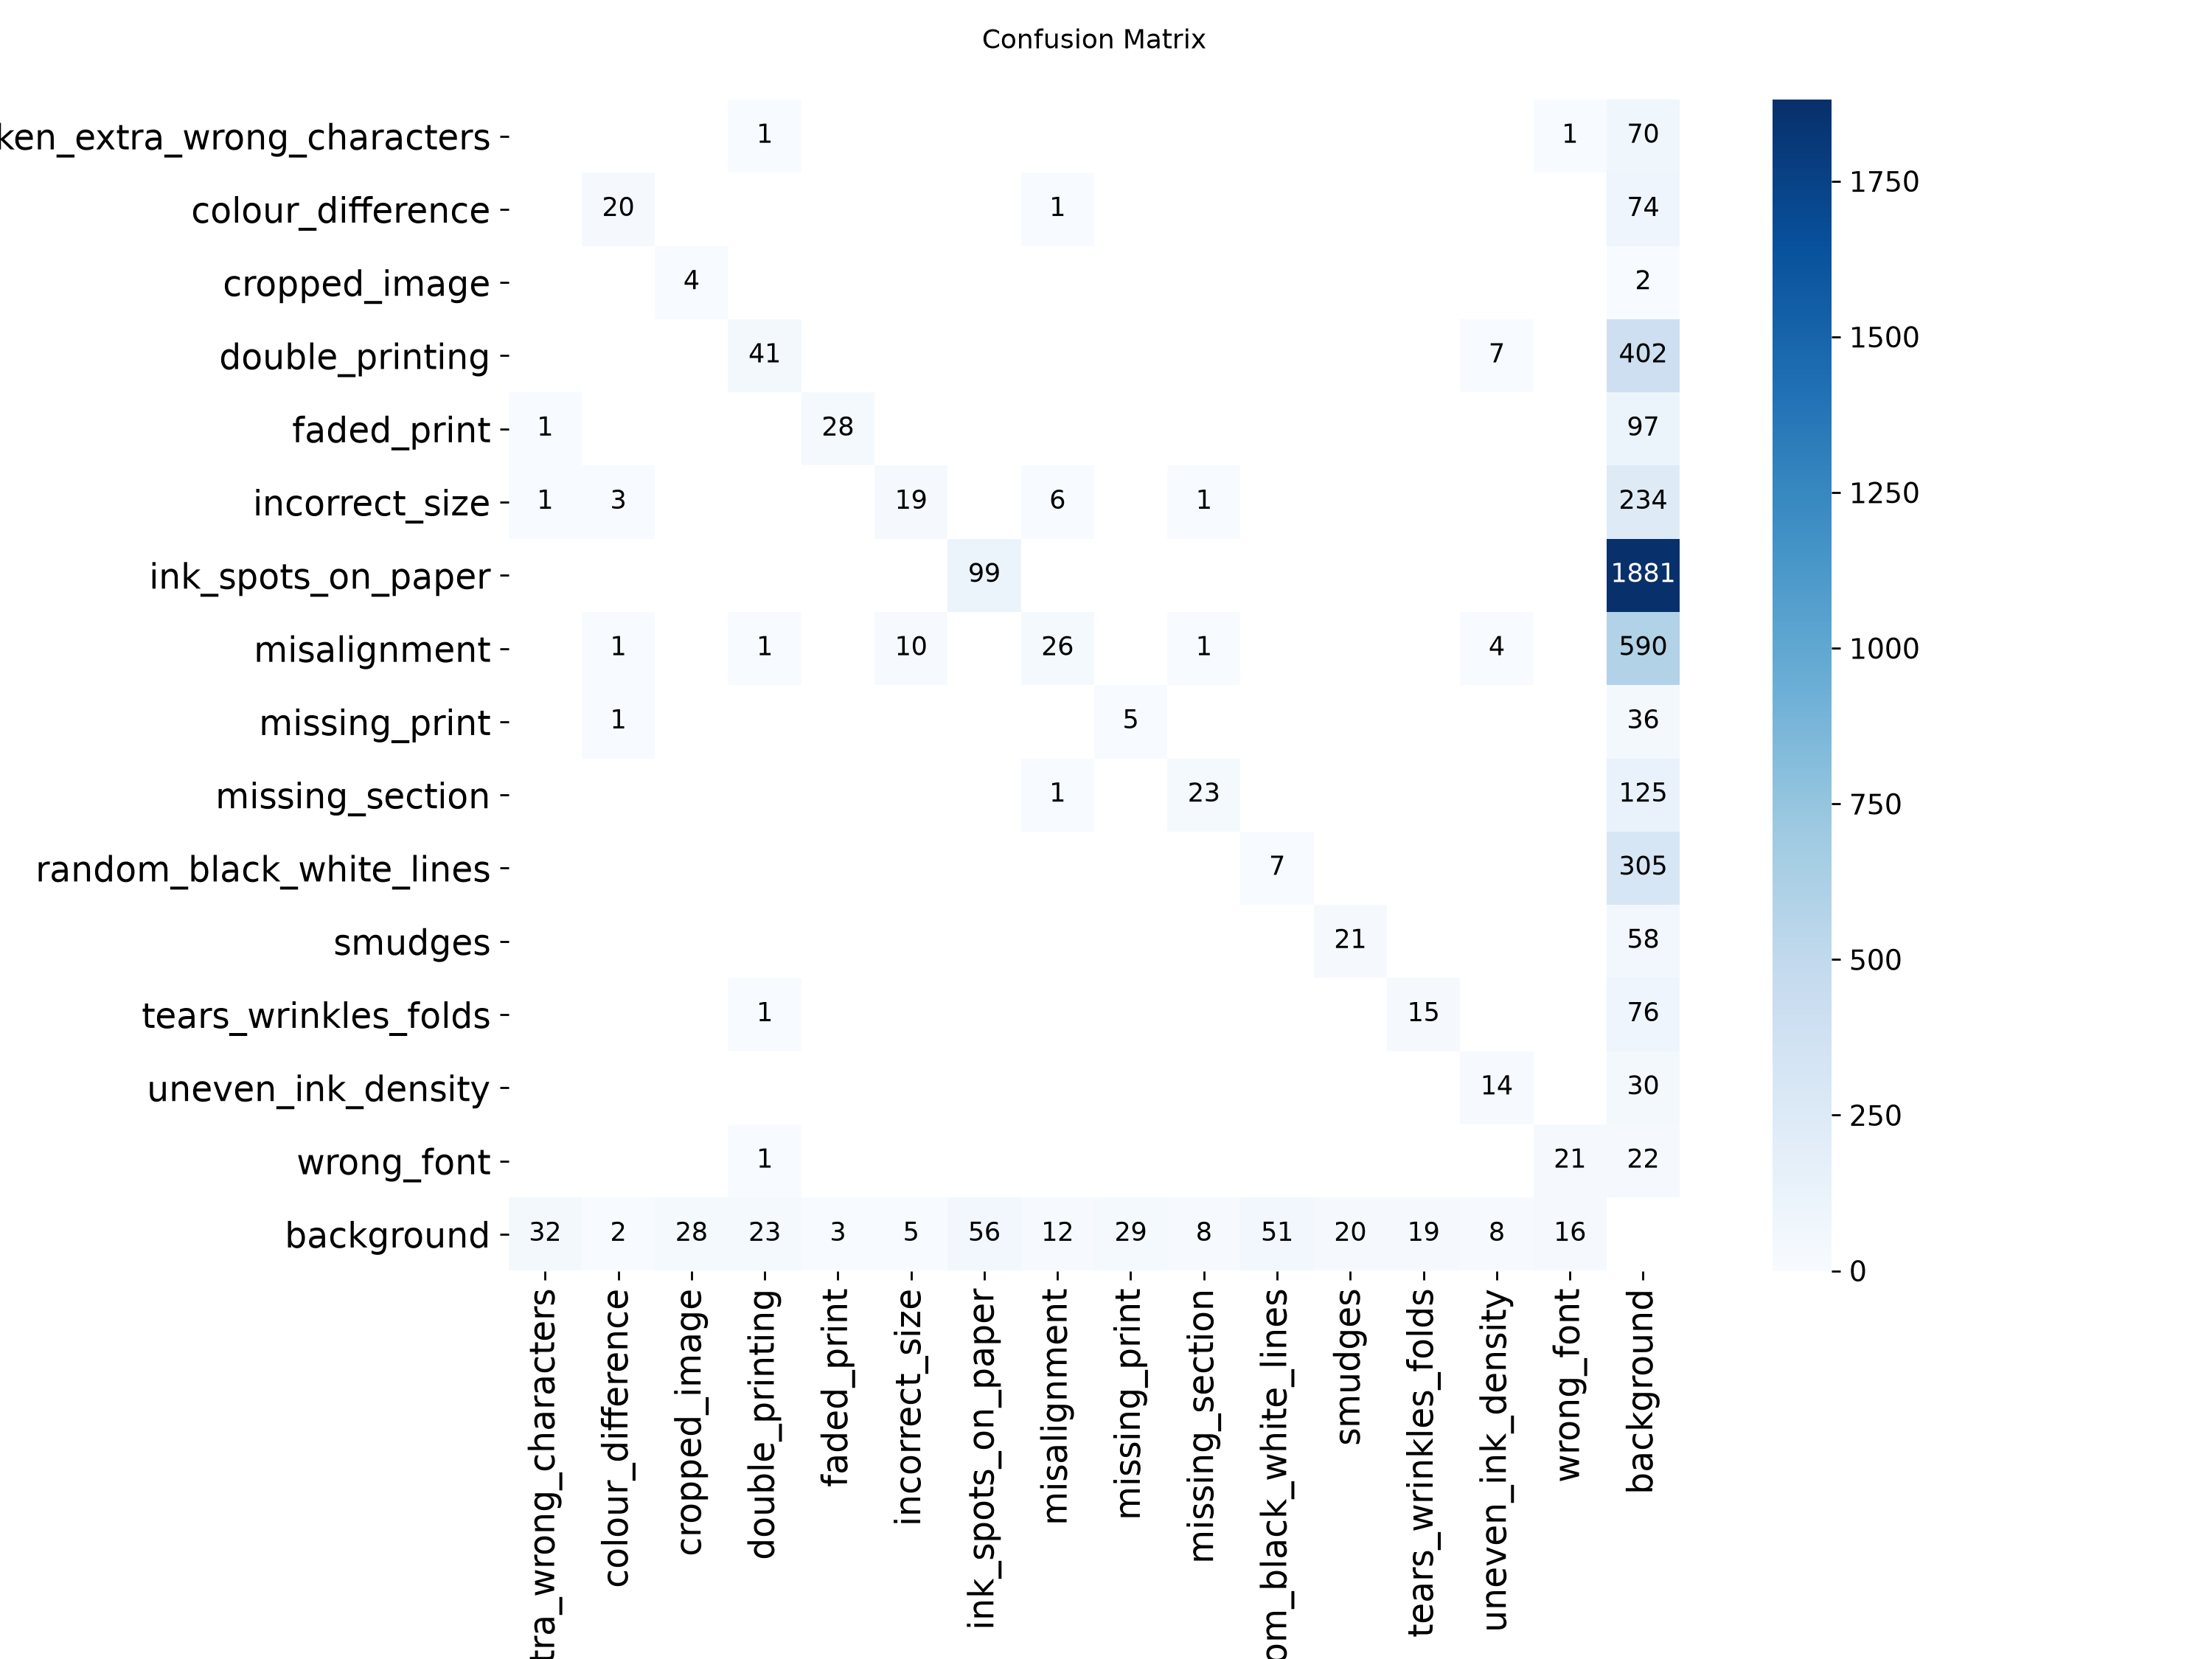

In [45]:
display(Image(filename=os.path.join(TEST_EVAL_DIR, "confusion_matrix.png")))


In [46]:
for fname in ["PR_curve.png", "F1_curve.png", "P_curve.png", "R_curve.png"]:
    fpath = os.path.join(TEST_EVAL_DIR, fname)
    if os.path.exists(fpath):
        print(fname)
        display(Image(filename=fpath))


## Step 13 — Run predictions on test images and save annotated examples

Now we run the trained model on the test images with `.predict()`, which draws
predicted bounding boxes + class labels + confidence scores on each image and saves
them. We then display a handful of examples inline.


In [47]:
PRED_RUN_NAME = RUN_NAME + "_test_predictions"

pred_results = best_model.predict(
    source=os.path.join(DATASET_DIR, "test", "images"),
    imgsz=IMG_SIZE,
    conf=0.25,
    save=True,
    save_txt=True,
    save_conf=True,
    project=os.path.join(RUNS_DIR, "detect"),
    name=PRED_RUN_NAME,
    exist_ok=True,
)

PRED_DIR = os.path.join(RUNS_DIR, "detect", PRED_RUN_NAME)
print("Annotated prediction images saved in:", PRED_DIR)



image 1/243 /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/test/images/broken_extra_wrong_characters_0058_jpg.rf.f8b85c469106d60112cbccd0aa3af7dd.jpg: 512x512 2 ink_spots_on_papers, 1321.0ms
image 2/243 /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/test/images/broken_extra_wrong_characters_0124_jpg.rf.7fe9d7e42a1a4e67958574d44cf61e64.jpg: 512x512 (no detections), 1201.9ms
image 3/243 /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/test/images/broken_extra_wrong_characters_0136_jpg.rf.9dce9499d6b4dc0e7db6277521dd2c94.jpg: 512x512 (no detections), 679.3ms
image 4/243 /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/test/images/broken_extra_wrong_characters_0139_jpg.rf.bb81d8135eb4b4543c0035497d801635.jpg: 512x512 (no detections), 1531.9ms
image 5/243 /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/test/images/colour_difference_0006_jpg.rf.93eab6f1a919019b221ddc4ebe430ac4.jpg: 512x512 1 colour_difference, 1366.8ms
image 6/243 /home/23CSU030/PRINT_DEFECT_PROJECT/Dataset/test/images/colour_difference_0010_j

In [49]:
pred_images = sorted(glob(os.path.join(PRED_DIR, "*.jpg")))
print(f"Total annotated test images: {len(pred_images)}")


Total annotated test images: 243


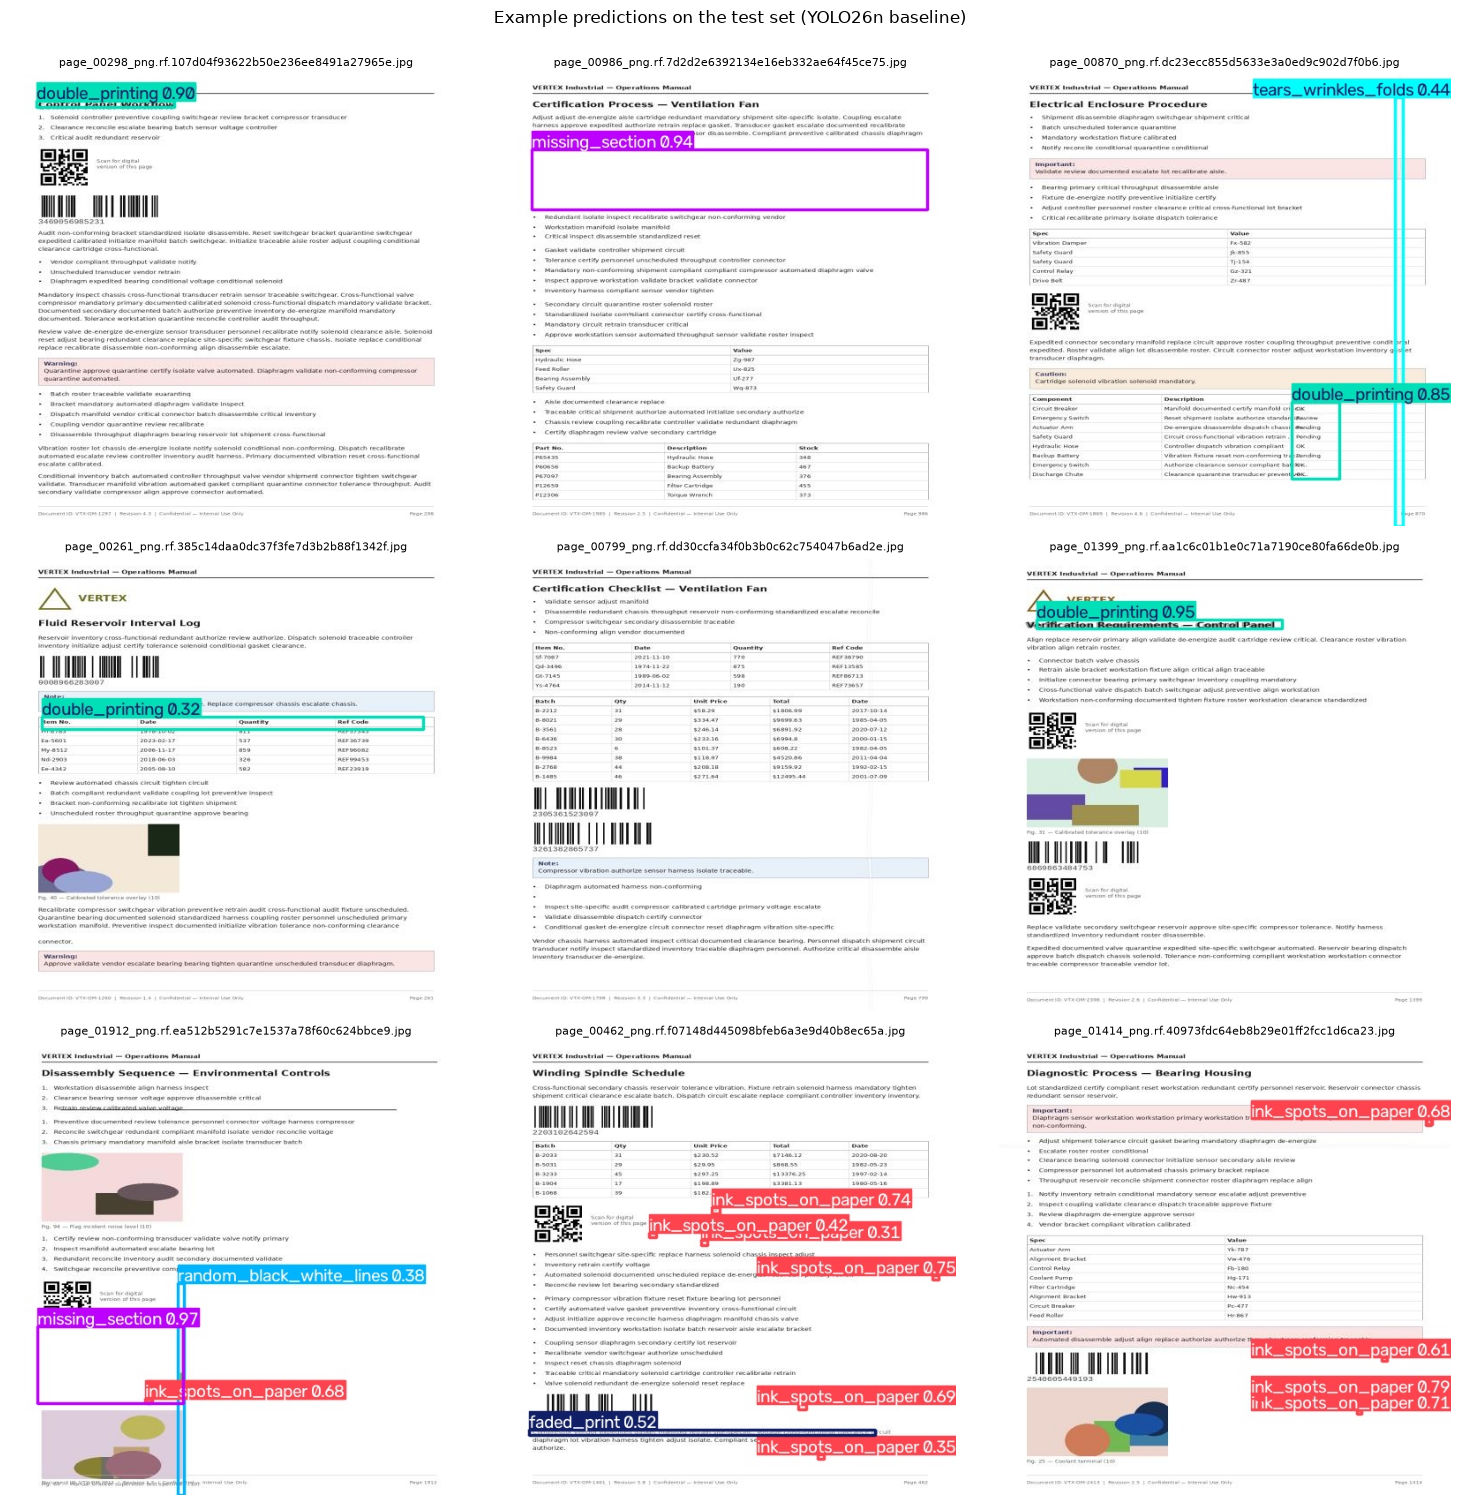

In [50]:
# Display a random sample of annotated predictions
sample_preds = random.sample(pred_images, min(9, len(pred_images)))

cols = 3
rows = (len(sample_preds) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(15, 5 * rows))
axes = axes.flatten()

for ax, img_path in zip(axes, sample_preds):
    img = cv2.cvtColor(cv2.imread(img_path), cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    ax.set_title(os.path.basename(img_path), fontsize=8)
    ax.axis("off")

for ax in axes[len(sample_preds):]:
    ax.axis("off")

plt.suptitle("Example predictions on the test set (YOLO26n baseline)", y=1.0)
plt.tight_layout()
plt.show()


## Step 14 — Which defects are detected well, and which perform poorly?

We rank all 15 classes by test mAP@0.5 and clearly separate the strong performers
from the weak ones — the same view as in your YOLOv5s and YOLOv8s notebooks, so you can
compare which classes are hard across all three models vs. which ones only one model
struggles with.


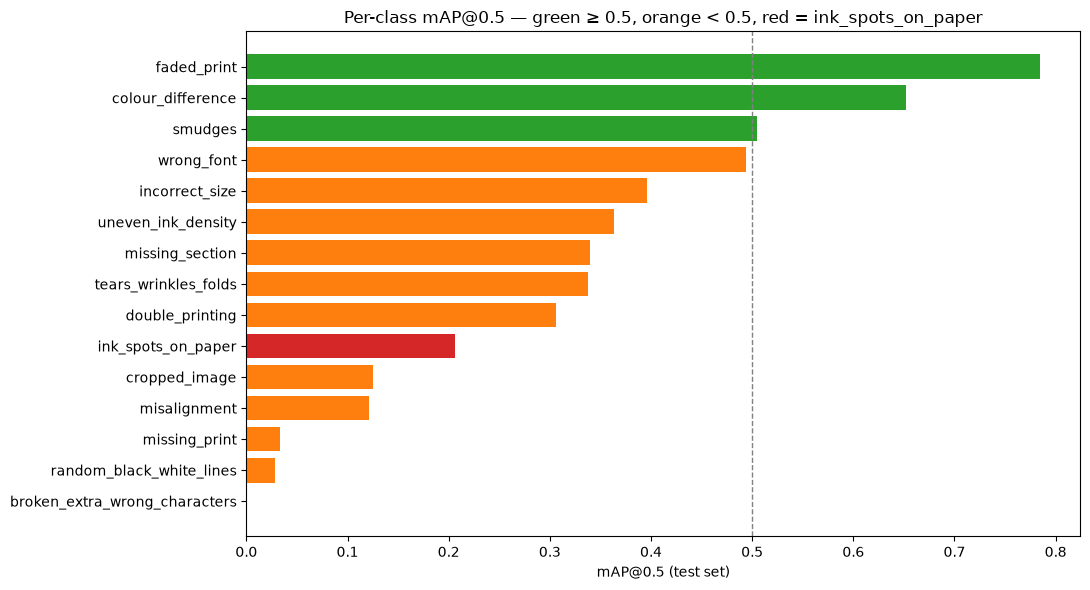

In [51]:
ranked_df = classwise_df.sort_values("mAP@0.5", ascending=False).reset_index(drop=True)

plt.figure(figsize=(11, 6))
colors = ["#d62728" if name == "ink_spots_on_paper" else "#2ca02c" if map50 >= 0.5 else "#ff7f0e"
          for name, map50 in zip(ranked_df["class_name"], ranked_df["mAP@0.5"])]
plt.barh(ranked_df["class_name"], ranked_df["mAP@0.5"], color=colors)
plt.gca().invert_yaxis()
plt.xlabel("mAP@0.5 (test set)")
plt.title("Per-class mAP@0.5 — green ≥ 0.5, orange < 0.5, red = ink_spots_on_paper")
plt.axvline(0.5, color="gray", linestyle="--", linewidth=1)
plt.tight_layout()
plt.show()


In [52]:
N_TOP = 5
N_BOTTOM = 5

print("=" * 60)
print(f"TOP {N_TOP} best-detected defect classes (highest mAP@0.5)")
print("=" * 60)
for _, row in ranked_df.head(N_TOP).iterrows():
    print(f"  {row['class_name']:35s}  mAP@0.5={row['mAP@0.5']:.3f}  "
          f"P={row['precision']:.3f}  R={row['recall']:.3f}  F1={row['F1']:.3f}  "
          f"(n={int(row['instances'])})")

print("\n" + "=" * 60)
print(f"BOTTOM {N_BOTTOM} worst-detected defect classes (lowest mAP@0.5)")
print("=" * 60)
for _, row in ranked_df.tail(N_BOTTOM).sort_values("mAP@0.5").iterrows():
    print(f"  {row['class_name']:35s}  mAP@0.5={row['mAP@0.5']:.3f}  "
          f"P={row['precision']:.3f}  R={row['recall']:.3f}  F1={row['F1']:.3f}  "
          f"(n={int(row['instances'])})")

print("\nNote: classes with very few test instances (small 'n') can have noisy metrics —")
print("check the 'instances' column before drawing strong conclusions about a class.")


TOP 5 best-detected defect classes (highest mAP@0.5)
  faded_print                          mAP@0.5=0.785  P=0.786  R=0.710  F1=0.746  (n=31)
  colour_difference                    mAP@0.5=0.652  P=0.645  R=0.519  F1=0.575  (n=27)
  smudges                              mAP@0.5=0.504  P=0.815  R=0.463  F1=0.591  (n=41)
  wrong_font                           mAP@0.5=0.494  P=0.851  R=0.316  F1=0.461  (n=38)
  incorrect_size                       mAP@0.5=0.396  P=0.408  R=0.647  F1=0.500  (n=34)

BOTTOM 5 worst-detected defect classes (lowest mAP@0.5)
  broken_extra_wrong_characters        mAP@0.5=0.000  P=0.000  R=0.000  F1=0.000  (n=34)
  random_black_white_lines             mAP@0.5=0.028  P=0.162  R=0.034  F1=0.057  (n=58)
  missing_print                        mAP@0.5=0.034  P=0.000  R=0.000  F1=0.000  (n=34)
  misalignment                         mAP@0.5=0.121  P=0.111  R=0.304  F1=0.162  (n=46)
  cropped_image                        mAP@0.5=0.125  P=1.000  R=0.087  F1=0.159  (n=32)


## Step 15 — Save everything

We zip up the training run (weights, curves, confusion matrix, class-wise CSV) and the
test evaluation + prediction folders, so you have one archive with everything needed
for your report and for comparing against YOLOv5s and YOLOv8s.


In [53]:
# Show the configured output folders (no hard-coded server/home path).
print("Project directory:", PROJECT_DIR)
print("Runs directory:", RUNS_DIR)
if os.path.isdir(RUNS_DIR):
    print(os.listdir(RUNS_DIR))
else:
    print("Runs directory has not been created yet.")


Project directory: /home/23CSU030/PRINT_DEFECT_PROJECT
Runs directory: /home/23CSU030/PRINT_DEFECT_PROJECT/runs
['train', 'detect', 'val']


In [54]:
print("Runs directory contents:", os.listdir(RUNS_DIR) if os.path.isdir(RUNS_DIR) else "Not created yet")


Runs directory contents: ['train', 'detect', 'val']


In [55]:
for _subdir in ["train", "val", "detect"]:
    _path = os.path.join(RUNS_DIR, _subdir)
    print(_path, "->", os.listdir(_path) if os.path.isdir(_path) else "Not created yet")


/home/23CSU030/PRINT_DEFECT_PROJECT/runs/train -> ['baseline_yolov5s', 'baseline_yolov8s', 'baseline_yolo11s', 'baseline_yolo26n']
/home/23CSU030/PRINT_DEFECT_PROJECT/runs/val -> ['baseline_yolov8s_test_eval', 'baseline_yolo11s_test_eval', 'baseline_yolo26n_test_eval', 'baseline_yolov5s_test_eval']
/home/23CSU030/PRINT_DEFECT_PROJECT/runs/detect -> ['baseline_yolo26n_test_predictions', 'baseline_yolov8s_test_predictions', 'baseline_yolo11s_test_predictions', 'baseline_yolov5s_test_predictions']


In [56]:
TRAIN_RUN_DIR = os.path.join(RUNS_DIR, "train", RUN_NAME)
TEST_EVAL_DIR = os.path.join(RUNS_DIR, "val", RUN_NAME + "_test_eval")
PRED_DIR = os.path.join(RUNS_DIR, "detect", RUN_NAME + "_test_predictions")

for _path in [TRAIN_RUN_DIR, TEST_EVAL_DIR, PRED_DIR]:
    print(_path, "exists:", os.path.isdir(_path))


/home/23CSU030/PRINT_DEFECT_PROJECT/runs/train/baseline_yolo26n exists: True
/home/23CSU030/PRINT_DEFECT_PROJECT/runs/val/baseline_yolo26n_test_eval exists: True
/home/23CSU030/PRINT_DEFECT_PROJECT/runs/detect/baseline_yolo26n_test_predictions exists: True


In [57]:
print(type(counts))
print(counts)

<class 'dict'>
{'train': 2538, 'val': 487, 'test': 243}


In [58]:
import shutil
import json

SAVE_ROOT = os.path.join(PROJECT_DIR, "yolo26n_baseline_results")
os.makedirs(SAVE_ROOT, exist_ok=True)

shutil.copytree(TRAIN_RUN_DIR, os.path.join(SAVE_ROOT, "train"), dirs_exist_ok=True)
shutil.copytree(TEST_EVAL_DIR, os.path.join(SAVE_ROOT, "test_eval"), dirs_exist_ok=True)
shutil.copytree(PRED_DIR, os.path.join(SAVE_ROOT, "test_predictions"), dirs_exist_ok=True)

display_df.to_csv(os.path.join(SAVE_ROOT, "classwise_test_metrics.csv"), index=False)
with open(os.path.join(SAVE_ROOT, "overall_test_metrics.json"), "w", encoding="utf-8") as f:
    json.dump({
        "precision": overall_precision,
        "recall": overall_recall,
        "mAP@0.5": overall_map50,
        "mAP@0.5:0.95": overall_map5095,
        "F1": overall_f1,
        "test_images": counts["test"],
        "test_instances": int(classwise_df["instances"].sum()),
    }, f, indent=2)

zip_path = shutil.make_archive(SAVE_ROOT, "zip", SAVE_ROOT)
print("Saved everything to:", zip_path)


Saved everything to: /home/23CSU030/PRINT_DEFECT_PROJECT/yolo26n_baseline_results.zip


In [59]:
# No Colab download step needed — the results zip already sits on the server.
print("Results zip saved at:", zip_path)
# Copy it to your own machine from a LOCAL terminal, e.g.:
# scp 23CSU030@<server-address>:"${zip_path}" .


Results zip saved at: /home/23CSU030/PRINT_DEFECT_PROJECT/yolo26n_baseline_results.zip


## Summary & next steps

You now have a complete **YOLO26n baseline** for your printing-defect dataset, built
the same way as your YOLOv5s and YOLOv8s baselines. That means **Phase 3 is done** —
you have three directly-comparable baselines:

- Overall test-set Precision, Recall, mAP@0.5, mAP@0.5:0.95, and F1 (Step 9)
- A full class-wise performance table for all 15 classes (Step 10)
- `ink_spots_on_paper` reported separately, with its class-imbalance context noted
  (Step 11)
- Confusion matrix + PR/F1/P/R curves on the test set (Step 12)
- Annotated example predictions on test images (Step 13)
- A ranked list of best- vs. worst-detected defect classes (Step 14)
- Everything zipped and saved (Step 15)

**According to your plan, next you'll:**
- **Phase 4:** Line up the class-wise tables from all three baselines
  (YOLOv5s / YOLOv8s / YOLO26n) side by side and identify which defects are
  *consistently* difficult, regardless of model — those are your genuinely hard
  classes, not just a quirk of one architecture.
- **Phase 5:** Use those consistently difficult classes to motivate your novelty —
  e.g. the *defect-aware spatial-frequency feature enhancement* idea from your notes.
- **Phase 6:** Once the novelty is implemented, re-run this same evaluation pipeline
  on it so its numbers are directly comparable to these three baselines.
- **Phase 7:** Once you're ready to test augmentation, remove (or reduce) the
  `NO_AUGMENTATION_PARAMS` overrides in Step 6 (and the equivalent in the other two
  notebooks) and re-run, then compare results specifically for the classes that
  struggled here.
